In [ ]:
from google.colab import drive; drive.mount('/content/drive')
import os, re, json, glob, itertools
import numpy as np, pandas as pd
pd.set_option("display.width", 200)

P9 = "/content/drive/MyDrive/Grad_share/data_share/P9"
SC = f"{P9}/SCORE/scored"          # ★ 라벨 파일 위치
Z_DIR = f"{P9}/SCORE"              # zones_192.parquet, label_KEY.csv 위치

for d in [SC, Z_DIR]:
    print(f"\n=== {d} ===")
    for f in sorted(glob.glob(f"{d}/*")):
        print(f"  {os.path.basename(f):45} {os.path.getsize(f)/1e3:8.1f} KB")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== /content/drive/MyDrive/Grad_share/data_share/P9/SCORE/scored ===
  label_A.csv                                       56.4 KB
  label_A.gsheet                                     0.2 KB
  label_B.csv                                       60.1 KB
  label_B.gsheet                                     0.2 KB
  label_C.csv                                       54.5 KB
  label_C.gsheet                                     0.2 KB

=== /content/drive/MyDrive/Grad_share/data_share/P9/SCORE ===
  judge_blind_192.csv                               91.6 KB
  judge_key_192.csv                                  6.0 KB
  label_A.csv                                       55.4 KB
  label_A.gsheet                                     0.2 KB
  label_B.csv                                       57.9 KB
  label_C.csv                                       53.5 KB
  label_KEY.csv   

In [ ]:
P9   = "/content/drive/MyDrive/Grad_share/data_search/P9"   # 오타 주의, 아래가 정답
P9   = "/content/drive/MyDrive/Grad_share/data_share/P9"
SC   = f"{P9}/SCORE/scored"    # ★ 수정된 라벨
Z_DIR = f"{P9}/SCORE"          # label_KEY.csv, zones_192.parquet

In [ ]:
def load_label(k):
    d = pd.read_csv(f"{SC}/label_{k}.csv")
    cid = "case_id" if "case_id" in d.columns else d.columns[0]
    d = d.rename(columns={cid:"case_id"})[["case_id","verdict"]].copy()
    d["verdict"] = pd.to_numeric(d.verdict, errors="coerce")
    d["rater"] = k
    return d

L = pd.concat([load_label(k) for k in "ABC"], ignore_index=True)
print("총", len(L), "| 결측", L.verdict.isna().sum())
print(L.groupby("rater").verdict.value_counts().unstack(fill_value=0).to_string())

CHK = {"A":{30:2, 47:1, 75:7}, "B":{123:7, 188:7}, "C":{247:7, 252:7, 302:7}}
for k, d in CHK.items():
    cur = L[L.rater==k].set_index("case_id").verdict
    for cid, want in d.items():
        got = cur.get(cid)
        print(f"  {k} case {cid}: {got} {'OK' if got==want else f'X (기대 {want})'}")

M3 = {1:"GOLD",2:"GOLD",3:"GOLD",4:"CTX",5:"CTX",6:"NONE",7:"NONE"}
L["v3"] = L.verdict.map(M3)

총 404 | 결측 0
verdict   1   2  3   4  5   6   7
rater                            
A        18  71  1  21  0  10  14
B        15  71  4  18  0   8  19
C        12  78  2  17  3   8  14
  A case 30: 2 OK
  A case 47: 1 OK
  A case 75: 7 OK
  B case 123: 7 OK
  B case 188: 7 OK
  C case 247: 7 OK
  C case 252: 7 OK
  C case 302: 7 OK


In [ ]:
KEY = pd.read_csv(f"{Z_DIR}/label_KEY.csv")
Z   = pd.read_parquet(f"{Z_DIR}/zones_192.parquet")

In [ ]:
W = L.pivot(index="case_id", columns="rater", values="verdict")
common = W.dropna().index
print(f"3인 공통 {len(common)}건\n")

def kappa(x, y):
    labs = sorted(set(x)|set(y)); n = len(x)
    po = np.mean([a==b for a,b in zip(x,y)])
    pe = sum((sum(a==l for a in x)/n)*(sum(b==l for b in y)/n) for l in labs)
    return ((po-pe)/(1-pe) if pe<1 else 1.0), po

for a,b in itertools.combinations("ABC",2):
    x, y = W.loc[common,a].tolist(), W.loc[common,b].tolist()
    k7,p7 = kappa(x,y)
    k3,p3 = kappa([M3[i] for i in x], [M3[i] for i in y])
    print(f"{a}-{b}  7범주 κ={k7:.3f} 일치={p7:.3f} | 3범주 κ={k3:.3f} 일치={p3:.3f}")

W3 = W.loc[common].apply(lambda c: c.map(M3))
dis = W3[W3.nunique(axis=1)>1]
print(f"\n3범주 불일치 {len(dis)}건")
if len(dis): print(dis.join(W.loc[dis.index], rsuffix="_7").to_string())

3인 공통 50건

A-B  7범주 κ=1.000 일치=1.000 | 3범주 κ=1.000 일치=1.000
A-C  7범주 κ=0.855 일치=0.900 | 3범주 κ=1.000 일치=1.000
B-C  7범주 κ=0.855 일치=0.900 | 3범주 κ=1.000 일치=1.000

3범주 불일치 0건


In [ ]:
Z_DIR = f"{P9}/SCORE"
lab = L.sort_values("rater").drop_duplicates("case_id").set_index("case_id").v3
KEY = pd.read_csv(f"{Z_DIR}/label_KEY.csv")
KEY["human"] = KEY.case_id.map(lab)
print("KEY", len(KEY), "| 라벨 결측", KEY.human.isna().sum())
print(KEY.task.value_counts().to_dict())

au = KEY[KEY.task=="audit"].dropna(subset=["human"])
print(f"\n=== 자동 규칙 정확도 {(au.zone==au.human).mean():.3f} (n={len(au)}) ===")
print(pd.crosstab(au.zone, au.human, margins=True).to_string())
print("\n조건별 ★오류가 조건에 몰리는지")
print(au.groupby("cond").apply(lambda d: pd.Series(
      {"n":len(d), "acc":(d.zone==d.human).mean()})).round(3).to_string())
mis = au[au.zone!=au.human]
print(f"\n--- 불일치 {len(mis)}건 ---")
print(mis[["case_id","cond","zone","reason","human"]].to_string())

KEY 304 | 라벨 결측 0
{'judge': 196, 'audit': 108}

=== 자동 규칙 정확도 0.852 (n=108) ===
human  CTX  GOLD  NONE  All
zone                       
CTX     30     1     5   36
GOLD     0    34     2   36
NONE     1     7    28   36
All     31    42    35  108

조건별 ★오류가 조건에 몰리는지
               n    acc
cond                   
baseline    27.0  0.963
front_all   27.0  0.889
gold_v1     27.0  0.741
signal_all  27.0  0.815

--- 불일치 16건 ---
     case_id        cond  zone     reason human
15        15   front_all   CTX   ctx_only  NONE
49        49  signal_all   CTX   ctx_only  NONE
64        64   front_all  GOLD  gold_only  NONE
65        65     gold_v1  NONE    neither  GOLD
101      101    baseline  NONE    neither  GOLD
129      129  signal_all   CTX   ctx_only  GOLD
135      135     gold_v1   CTX   ctx_only  NONE
144      144  signal_all  NONE    neither  GOLD
179      179   front_all  NONE    neither  GOLD
180      180     gold_v1  NONE    neither  GOLD
219      219  signal_all  NONE    neither   

/tmp/ipykernel_2565/3445422183.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(au.groupby("cond").apply(lambda d: pd.Series(


In [ ]:
v7 = L.sort_values("rater").drop_duplicates("case_id").set_index("case_id").verdict
ju = KEY[KEY.task=="judge"].dropna(subset=["human"])
p = ju.groupby("cond").human.agg(n="size", p_gold=lambda s:(s=="GOLD").mean())
p["se"] = np.sqrt(p.p_gold*(1-p.p_gold)/p.n)
print("=== 조건별 P(GOLD|JUDGE) ===")
print(p.round(3).to_string())
print("\n7범주 내역:")
print(pd.crosstab(ju.cond, ju.case_id.map(v7)).to_string())

=== 조건별 P(GOLD|JUDGE) ===
             n  p_gold     se
cond                         
baseline    40   0.825  0.060
front_all   46   0.870  0.050
gold_v1     50   0.860  0.049
signal_all  60   0.900  0.039

7범주 내역:
case_id      2  3  4  5  6  7
cond                         
baseline    33  0  2  1  1  3
front_all   37  3  3  0  1  2
gold_v1     42  1  2  0  1  4
signal_all  51  3  2  0  0  4


In [ ]:
Z = pd.read_parquet(f"{Z_DIR}/zones_192.parquet")
CONDS = ["baseline","front_all","gold_v1","signal_all"]
pairs = pd.read_csv(f"{P9}/p8s_behavior.csv")
Z = Z[Z.cond.isin(CONDS) & Z.seed.isin([-1,0])].copy()
Z["q"] = pairs.loc[Z.row,"question"].values
piv = Z.pivot_table(index="q", columns="cond", values="zone", aggfunc="first").dropna()
qs = piv.index.values; print("공통 질문", len(qs))

ZN = ["GOLD","CTX","NONE","JUDGE"]
cells = {}                       # (cond, zone) -> 0/1 배열
for c in CONDS:
    for z in ZN:
        src = au if z!="JUDGE" else ju
        v = src[(src.cond==c) & ((src.zone==z) if z!="JUDGE" else True)]
        cells[(c,z)] = (v.human=="GOLD").values.astype(int)
print("\n구역별 표본 수 / GOLD율")
for c in CONDS:
    print(" ", c, {z:(len(cells[(c,z)]), round(cells[(c,z)].mean(),2) if len(cells[(c,z)]) else None) for z in ZN})

def S_of(sub, q):
    return {c: sum((sub[c]==z).mean()*q[(c,z)] for z in ZN) for c in CONDS}

q0 = {k:(v.mean() if len(v) else 0.0) for k,v in cells.items()}
S0 = S_of(piv.loc[qs], q0)
print("\n=== 보정 성공률 ===")
for c in CONDS: print(f"  {c:12} S={S0[c]:.3f}")

rs = np.random.RandomState(0); B = 4000; boot=[]
for _ in range(B):
    qb = rs.choice(qs, len(qs), replace=True)
    qq = {k:(v[rs.randint(0,len(v),len(v))].mean() if len(v) else 0.0) for k,v in cells.items()}
    boot.append(S_of(piv.loc[qb], qq))
boot = pd.DataFrame(boot)

print("\n=== 순증 (baseline 대비, ×378) ===")
for c in CONDS[1:]:
    d=(boot[c]-boot.baseline)*378
    print(f"  {c:12} {(S0[c]-S0['baseline'])*378:+6.0f}  CI[{np.percentile(d,2.5):+.0f}, {np.percentile(d,97.5):+.0f}]")
print("\n=== 조건 간 비교 ★층 결론 ===")
for a,b in [("signal_all","front_all"),("signal_all","gold_v1"),("gold_v1","front_all")]:
    d=(boot[a]-boot[b])*378; ci=np.percentile(d,[2.5,97.5])
    print(f"  {a} − {b}: {(S0[a]-S0[b])*378:+6.0f}  CI[{ci[0]:+.0f}, {ci[1]:+.0f}]"
          f"  {'유의' if ci[0]*ci[1]>0 else '구별 불가'}")

공통 질문 378

구역별 표본 수 / GOLD율
  baseline {'GOLD': (9, np.float64(1.0)), 'CTX': (9, np.float64(0.0)), 'NONE': (9, np.float64(0.11)), 'JUDGE': (40, np.float64(0.82))}
  front_all {'GOLD': (9, np.float64(0.89)), 'CTX': (9, np.float64(0.0)), 'NONE': (9, np.float64(0.11)), 'JUDGE': (46, np.float64(0.87))}
  gold_v1 {'GOLD': (9, np.float64(0.89)), 'CTX': (9, np.float64(0.0)), 'NONE': (9, np.float64(0.33)), 'JUDGE': (50, np.float64(0.86))}
  signal_all {'GOLD': (9, np.float64(1.0)), 'CTX': (9, np.float64(0.11)), 'NONE': (9, np.float64(0.22)), 'JUDGE': (60, np.float64(0.9))}

=== 보정 성공률 ===
  baseline     S=0.511
  front_all    S=0.565
  gold_v1      S=0.612
  signal_all   S=0.697

=== 순증 (baseline 대비, ×378) ===
  front_all       +20  CI[-14, +49]
  gold_v1         +38  CI[+3, +70]
  signal_all      +70  CI[+40, +102]

=== 조건 간 비교 ★층 결론 ===
  signal_all − front_all:    +50  CI[+16, +88]  유의
  signal_all − gold_v1:    +32  CI[-3, +71]  구별 불가
  gold_v1 − front_all:    +18  CI[-21, +58]  구별 불가


## 자동 채점기 진행

In [ ]:
## B1-0 환경 (A100 확인)
!pip install -q "transformers==4.44.2" accelerate 2>&1|tail -1
from google.colab import drive; drive.mount('/content/drive')
import os, re, json, numpy as np, pandas as pd, torch
from tqdm.auto import tqdm
print(torch.cuda.get_device_name(0))
P9="/content/drive/MyDrive/Grad_share/data_share/P9"; SC=f"{P9}/SCORE"

ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (tokenizers)
Mounted at /content/drive
NVIDIA A100-SXM4-40GB


In [ ]:
## B1-1 데이터: 사람 라벨 304건 + 원문 결합
L=pd.concat([pd.read_csv(f"{SC}/scored/label_{k}.csv").rename(
      columns={"Unnamed: 0":"case_id"})[["case_id","verdict"]].assign(rater=k) for k in "ABC"])
L["verdict"]=pd.to_numeric(L.verdict,errors="coerce")
M3={1:"GOLD",2:"GOLD",3:"GOLD",4:"CTX",5:"CTX",6:"NONE",7:"NONE"}
lab=L.sort_values("rater").drop_duplicates("case_id").set_index("case_id")
KEY=pd.read_csv(f"{SC}/label_KEY.csv"); B=pd.read_csv(f"{SC}/judge_blind_192.csv")
D=KEY.merge(B[["case_id","question","gold","ctx","gen"]],on="case_id",how="left")
D["human"]=D.case_id.map(lab.verdict).map(M3)
D=D.dropna(subset=["human","gen"]).reset_index(drop=True)
rs=np.random.RandomState(7); m=rs.rand(len(D))<0.4
D["split"]=np.where(m,"dev","test")
print(len(D), D.split.value_counts().to_dict(), D.human.value_counts().to_dict())

201 {'test': 122, 'dev': 79} {'GOLD': 138, 'NONE': 35, 'CTX': 28}


In [ ]:
## B1-2 판정기: 4지선다 첫 토큰 logit (생성 없음)
from transformers import AutoTokenizer, AutoModelForCausalLM
MID="NousResearch/Meta-Llama-3.1-8B-Instruct"
tok=AutoTokenizer.from_pretrained(MID); tok.pad_token=tok.pad_token or tok.eos_token
tok.padding_side="left"
mdl=AutoModelForCausalLM.from_pretrained(MID,torch_dtype=torch.bfloat16,device_map="auto").eval()

TMPL=("You grade an AI answer. Judge ONLY what the answer finally asserts as true.\n"
      "Question: {q}\nCorrect answer: {g}\nMisleading answer from context: {c}\n"
      "AI answer: {a}\n\nWhich did it finally assert?\n"
      "A) the correct answer\nB) the misleading answer\n"
      "C) no answer given / refused\nD) some other answer / contradictory\n"
      "Reply with one letter.\nAnswer:")
IDS=[tok.encode(x,add_special_tokens=False)[0] for x in [" A"," B"," C"," D"]]
MAP={0:"GOLD",1:"CTX",2:"NONE",3:"NONE"}

@torch.no_grad()
def judge(df,bs=8):
    out=[]
    for s in tqdm(range(0,len(df),bs)):
        ch=df.iloc[s:s+bs]
        ps=[tok.apply_chat_template([{"role":"user","content":TMPL.format(
             q=r.question,g=", ".join(json.loads(r.gold))[:120],c=r.ctx,a=str(r.gen)[:900])}],
             add_generation_prompt=True,tokenize=False) for r in ch.itertuples()]
        enc=tok(ps,return_tensors="pt",padding=True,add_special_tokens=False).to(mdl.device)
        lg=mdl(**enc).logits[:,-1,:]
        out+= [MAP[i] for i in lg[:,IDS].argmax(-1).tolist()]
    return out
D["pred"]=judge(D)

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.9k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

  0%|          | 0/26 [00:00<?, ?it/s]

In [ ]:
## B1-3 검증 ★판정
def report(sub,name):
    acc=(sub.pred==sub.human).mean()
    f1=[]
    for c in ["GOLD","CTX","NONE"]:
        tp=((sub.pred==c)&(sub.human==c)).sum(); p=(sub.pred==c).sum(); r=(sub.human==c).sum()
        pr=tp/p if p else 0; rc=tp/r if r else 0
        f1.append(2*pr*rc/(pr+rc) if pr+rc else 0)
        print(f"    {c}: recall={rc:.3f} prec={pr:.3f}")
    print(f"  {name}: acc={acc:.3f} macroF1={np.mean(f1):.3f} "
          f"(최빈값 baseline={sub.human.value_counts(normalize=True).max():.3f})")
for nm,sub in [("dev",D[D.split=='dev']),("TEST",D[D.split=='test'])]:
    print(f"\n=== {nm} n={len(sub)} ==="); report(sub,nm)
print("\n혼동행렬(test)"); print(pd.crosstab(D[D.split=='test'].pred,D[D.split=='test'].human).to_string())
print("\n=== ★조건별 편향 (judge GOLD율 − 사람 GOLD율) ===")
print(D.groupby("cond").apply(lambda d: pd.Series({
    "n":len(d),"human":(d.human=="GOLD").mean(),"judge":(d.pred=="GOLD").mean(),
    "차이":(d.pred=="GOLD").mean()-(d.human=="GOLD").mean()})).round(3).to_string())


=== dev n=79 ===
    GOLD: recall=0.382 prec=0.808
    CTX: recall=0.267 prec=0.667
    NONE: recall=0.889 prec=0.170
  dev: acc=0.418 macroF1=0.395 (최빈값 baseline=0.696)

=== TEST n=122 ===
    GOLD: recall=0.337 prec=0.700
    CTX: recall=0.077 prec=0.071
    NONE: recall=0.385 prec=0.147
  TEST: acc=0.320 macroF1=0.247 (최빈값 baseline=0.680)

혼동행렬(test)
human  CTX  GOLD  NONE
pred                  
CTX      1     6     7
GOLD     3    28     9
NONE     9    49    10

=== ★조건별 편향 (judge GOLD율 − 사람 GOLD율) ===
               n  human  judge     차이
cond                                 
baseline    46.0  0.652  0.239 -0.413
front_all   47.0  0.638  0.298 -0.340
gold_v1     45.0  0.689  0.400 -0.289
signal_all  63.0  0.746  0.365 -0.381


/tmp/ipykernel_2683/3774228029.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(D.groupby("cond").apply(lambda d: pd.Series({


In [ ]:
print("case_id 겹침:", len(set(KEY.case_id)&set(B.case_id)), "/", len(KEY))
print("D 길이:", len(D), "(304여야 함)")
print("\n토큰 확인:")
for x in ["A","B","C","D"," A"," B"," C"," D"]:
    print(f"  {x!r} → {tok.encode(x, add_special_tokens=False)}")
print("\n샘플 대조 (case_id, gen 앞부분, human):")
print(D[["case_id","human"]].head(3).to_string())
print(D.gen.iloc[0][:150])

case_id 겹침: 201 / 304
D 길이: 201 (304여야 함)

토큰 확인:
  'A' → [32]
  'B' → [33]
  'C' → [34]
  'D' → [35]
  ' A' → [362]
  ' B' → [426]
  ' C' → [356]
  ' D' → [423]

샘플 대조 (case_id, gen 앞부분, human):
   case_id human
0        0   CTX
1        1  GOLD
2        2  NONE
The answer is George Roy Hill, not Xavier Gens. George Roy Hill directed the 1973 film "The Sting", not Xavier Gens. Xavier Gens is a different direct


In [ ]:
def load_full(k):
    d = pd.read_csv(f"{SC}/scored/label_{k}.csv")
    cid = "case_id" if "case_id" in d.columns else d.columns[0]
    return d.rename(columns={cid:"case_id"})[["case_id","question","gold","ctx","gen","verdict"]].assign(rater=k)

F = pd.concat([load_full(k) for k in "ABC"], ignore_index=True)
F["verdict"] = pd.to_numeric(F.verdict, errors="coerce")
F = F.sort_values("rater").drop_duplicates("case_id")
F["human"] = F.verdict.map(M3)

KEY = pd.read_csv(f"{SC}/label_KEY.csv")
D = KEY.merge(F[["case_id","question","gold","ctx","gen","human"]], on="case_id", how="inner")
print("D:", len(D), "(304여야 함)")
print(D.groupby("cond").human.apply(lambda s:(s=="GOLD").mean()).round(3).to_string())

D: 304 (304여야 함)
cond
baseline      0.642
front_all     0.671
gold_v1       0.701
signal_all    0.759


In [ ]:
IDS = [tok.encode(x, add_special_tokens=False)[0] for x in ["A","B","C","D"]]   # [32,33,34,35]
rs = np.random.RandomState(7); D["split"] = np.where(rs.rand(len(D))<0.4, "dev", "test")
D["pred"] = judge(D)

def report(sub, name):
    f1=[]
    for c in ["GOLD","CTX","NONE"]:
        tp=((sub.pred==c)&(sub.human==c)).sum(); p=(sub.pred==c).sum(); r=(sub.human==c).sum()
        pr=tp/p if p else 0; rc=tp/r if r else 0
        f1.append(2*pr*rc/(pr+rc) if pr+rc else 0)
        print(f"    {c}: recall={rc:.3f} prec={pr:.3f}")
    print(f"  {name}: acc={(sub.pred==sub.human).mean():.3f} macroF1={np.mean(f1):.3f} "
          f"(최빈값 {sub.human.value_counts(normalize=True).max():.3f})")
for nm, sub in [("dev", D[D.split=="dev"]), ("TEST", D[D.split=="test"])]:
    print(f"\n=== {nm} n={len(sub)} ==="); report(sub, nm)
print("\n혼동행렬(test)"); print(pd.crosstab(D[D.split=="test"].pred, D[D.split=="test"].human).to_string())
print("\n=== ★조건별 편향 ===")
print(D.groupby("cond").apply(lambda d: pd.Series({
    "n":len(d), "human":(d.human=="GOLD").mean(), "judge":(d.pred=="GOLD").mean(),
    "차이":(d.pred=="GOLD").mean()-(d.human=="GOLD").mean()}), include_groups=False).round(3).to_string())

  0%|          | 0/38 [00:00<?, ?it/s]


=== dev n=122 ===
    GOLD: recall=0.795 prec=0.986
    CTX: recall=0.857 prec=0.783
    NONE: recall=0.769 prec=0.357
  dev: acc=0.803 macroF1=0.729 (최빈값 0.721)

=== TEST n=182 ===
    GOLD: recall=0.806 prec=0.926
    CTX: recall=0.850 prec=0.773
    NONE: recall=0.711 prec=0.519
  TEST: acc=0.791 macroF1=0.757 (최빈값 0.681)

혼동행렬(test)
human  CTX  GOLD  NONE
pred                  
CTX     17     2     3
GOLD     0   100     8
NONE     3    22    27

=== ★조건별 편향 ===
               n  human  judge     차이
cond                                 
baseline    67.0  0.642  0.507 -0.134
front_all   73.0  0.671  0.603 -0.068
gold_v1     77.0  0.701  0.623 -0.078
signal_all  87.0  0.759  0.609 -0.149


In [ ]:
## 판정기 재실행 — pred + margin 동시 저장
@torch.no_grad()
def judge2(df, bs=8):
    preds, margins = [], []
    for s in tqdm(range(0, len(df), bs)):
        ch = df.iloc[s:s+bs]
        ps = [tok.apply_chat_template([{"role":"user","content":TMPL.format(
               q=r.question, g=", ".join(json.loads(r.gold))[:120], c=r.ctx, a=str(r.gen)[:900])}],
               add_generation_prompt=True, tokenize=False) for r in ch.itertuples()]
        enc = tok(ps, return_tensors="pt", padding=True, add_special_tokens=False).to(mdl.device)
        lg = mdl(**enc).logits[:, -1, :][:, IDS].float()        # (B,4)
        top2 = lg.topk(2, dim=-1)
        preds += [MAP[i] for i in top2.indices[:,0].tolist()]
        margins += (top2.values[:,0] - top2.values[:,1]).tolist()
    return preds, margins

D["pred"], D["margin"] = judge2(D)
print(D.margin.describe().round(2).to_string())

  0%|          | 0/38 [00:00<?, ?it/s]

count    304.00
mean       2.11
std        1.56
min        0.00
25%        0.84
50%        1.81
75%        3.12
max        7.75


In [ ]:
## 커버리지-편향 곡선 ★
T = D[D.split=="test"]
print(f"{'임계':>6}{'커버리지':>10}{'acc':>8}{'편향폭':>9}  조건별 편향")
for th in [0, 0.5, 1, 2, 3, 4, 6, 8]:
    s = T[T.margin >= th]
    if len(s) < 20: continue
    b = s.groupby("cond").apply(lambda d: (d.pred=="GOLD").mean()-(d.human=="GOLD").mean(),
                                include_groups=False)
    print(f"{th:>6}{len(s)/len(T):>10.2f}{(s.pred==s.human).mean():>8.3f}"
          f"{b.max()-b.min():>9.3f}  {b.round(3).to_dict()}")

    임계      커버리지     acc      편향폭  조건별 편향
     0      1.00   0.786    0.247  {'baseline': -0.182, 'front_all': 0.047, 'gold_v1': -0.044, 'signal_all': -0.2}
   0.5      0.84   0.862    0.182  {'baseline': -0.154, 'front_all': 0.029, 'gold_v1': -0.083, 'signal_all': -0.143}
     1      0.73   0.909    0.080  {'baseline': -0.031, 'front_all': -0.032, 'gold_v1': -0.091, 'signal_all': -0.111}
     2      0.48   0.977    0.048  {'baseline': -0.043, 'front_all': 0.0, 'gold_v1': 0.0, 'signal_all': -0.048}
     3      0.30   1.000    0.000  {'baseline': 0.0, 'front_all': 0.0, 'gold_v1': 0.0, 'signal_all': 0.0}
     4      0.12   1.000    0.000  {'baseline': 0.0, 'front_all': 0.0, 'gold_v1': 0.0, 'signal_all': 0.0}


In [ ]:
import matplotlib.pyplot as plt
T = D[D.split=="test"]; n0 = len(T)
rows = []
for th in np.arange(0, 5.01, 0.25):
    s = T[T.margin >= th]
    if len(s) < 20: continue
    g = s.groupby("cond").apply(lambda d: (d.pred=="GOLD").mean()-(d.human=="GOLD").mean(),
                                include_groups=False)
    rows.append([float(th), len(s)/n0, float((s.pred==s.human).mean()),
                 float(g.max()-g.min())])
C = pd.DataFrame(rows, columns=["th","cov","acc","spread"])
print(C.round(3).to_string(index=False))

  th   cov   acc  spread
0.00 1.000 0.786   0.247
0.25 0.901 0.829   0.170
0.50 0.835 0.862   0.182
0.75 0.764 0.892   0.146
1.00 0.725 0.909   0.080
1.25 0.676 0.935   0.034
1.50 0.615 0.938   0.040
1.75 0.522 0.947   0.047
2.00 0.484 0.977   0.048
2.25 0.434 0.987   0.050
2.50 0.379 1.000   0.000
2.75 0.335 1.000   0.000
3.00 0.302 1.000   0.000
3.25 0.258 1.000   0.000
3.50 0.242 1.000   0.000
3.75 0.198 1.000   0.000
4.00 0.121 1.000   0.000


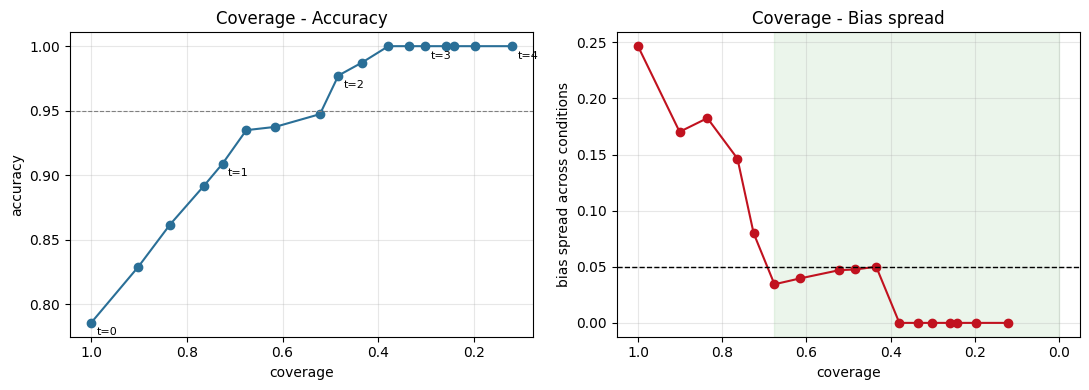

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
a = ax[0]; a.plot(C["cov"], C["acc"], "o-", color="#2a6f97")
for _, r in C.iterrows():
    if abs(r["th"] % 1) < 1e-9:
        a.annotate(f"t={r['th']:.0f}", (r["cov"], r["acc"]), fontsize=8,
                   xytext=(4,-9), textcoords="offset points")
a.axhline(0.95, ls="--", c="gray", lw=.8)
a.set_xlabel("coverage"); a.set_ylabel("accuracy"); a.set_title("Coverage - Accuracy")
a.invert_xaxis(); a.grid(alpha=.3)

a = ax[1]; a.plot(C["cov"], C["spread"], "o-", color="#c1121f")
a.axhline(0.05, ls="--", c="k", lw=1)
ok = C[C["spread"] <= 0.05]
if len(ok): a.axvspan(0, ok["cov"].max(), color="green", alpha=.08)
a.set_xlabel("coverage"); a.set_ylabel("bias spread across conditions")
a.set_title("Coverage - Bias spread"); a.invert_xaxis(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{P9}/T456/fig_hybrid_coverage.png", dpi=150); plt.show()

### T6 saturation?

In [ ]:
import numpy as np, pandas as pd, re, json, string
P9 = "/content/drive/MyDrive/Grad_share/data_share/P9"

def normalize(s):
    s = str(s).lower(); s = re.sub(r"\b(a|an|the)\b"," ",s)
    s = "".join(ch for ch in s if ch not in string.punctuation)
    return " ".join(s.split())
def match_gold(text, golds):
    t = normalize(text)
    return any(re.search(r"\b"+re.escape(normalize(g))+r"\b", t) for g in golds if str(g).strip())
REFUSAL_PAT = re.compile(r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to"
                         r"|no information|not sure)", re.IGNORECASE)

pairs = pd.read_csv(f"{P9}/p8s_behavior.csv")
HID   = np.load(f"{P9}/hid_p8s.npy")          # 641MB, 1~2분
ids   = np.load(f"{P9}/hid_p8s_ids.npy", allow_pickle=True)
assert (pairs["question"].values == ids).all(), "★ 행 정렬 불일치"
kpcm  = pairs[(pairs.kside=="K+")&(pairs.ctx_label=="C-")].index.values
print(pairs.shape, HID.shape, "| kpcm", len(kpcm))

(1224, 19) (1224, 131072) | kpcm 378


In [ ]:
def layer(H,L): return H[:, (L-1)*4096:L*4096]
def dom(H, ma, mb):
    W = np.zeros((32,4096), np.float32)
    for L in range(1,33):
        HL = layer(H,L); d = HL[ma].mean(0) - HL[mb].mean(0)
        W[L-1] = d/(np.linalg.norm(d)+1e-8)
    return W

def lab_sf3(r):
    a = str(r["answer"])
    if REFUSAL_PAT.search(a): return "abstain"
    hc, hp = match_gold(a,[r["answer_surface"]]), match_gold(a,[r["A_cb"]])
    return "both" if (hc and hp) else "accept" if hc else "retain" if hp else "other"
pairs["sf3"] = pairs.apply(lab_sf3, axis=1)

sf   = pairs.loc[kpcm,"sf3"].replace({"both":"retain"}).values   # both→retain 정책 고정
keep = np.isin(sf, ["accept","retain"])
IDX, LB = kpcm[keep], sf[keep]
W_ALL = dom(HID[IDX], LB=="accept", LB=="retain")
print(f"전체 w 표본 {len(IDX)} | accept {(LB=='accept').sum()} retain {(LB=='retain').sum()}")

전체 w 표본 303 | accept 170 retain 133


In [ ]:
BLK = {"front":[8,9,10,11,12], "signal":[14,15,16,17,18]}
NS  = [10,20,30,50,100,150,200,len(IDX)]
rows = []
for N in NS:
    for sd in range(5):                                  # 5시드
        rs  = np.random.RandomState(1000+sd)
        sub = rs.choice(len(IDX), min(N,len(IDX)), replace=False)
        lb  = LB[sub]
        if (lb=="accept").sum()<2 or (lb=="retain").sum()<2: continue
        w = dom(HID[IDX[sub]], lb=="accept", lb=="retain")
        r = {"N":N, "seed":sd}
        for b,Ls in BLK.items():
            r[b] = float(np.mean([w[L] @ W_ALL[L] for L in Ls]))
        r["all32"] = float(np.mean([w[L] @ W_ALL[L] for L in range(32)]))
        rows.append(r)
S = pd.DataFrame(rows)
agg = S.groupby("N")[["front","signal","all32"]].agg(["mean","std"]).round(3)
print("=== 전체 w와의 cos ===")
print(agg.to_string())

print("\n=== 층별 상세 (N=30) ===")
r30 = S[S.N==30]
print(f"  front  {r30.front.mean():.3f} ± {r30.front.std():.3f}")
print(f"  signal {r30.signal.mean():.3f} ± {r30.signal.std():.3f}")

=== 전체 w와의 cos ===
     front        signal         all32       
      mean    std   mean    std   mean    std
N                                            
10   0.354  0.272  0.417  0.298  0.387  0.267
20   0.452  0.241  0.600  0.196  0.527  0.189
30   0.519  0.287  0.702  0.139  0.610  0.202
50   0.682  0.151  0.807  0.066  0.738  0.107
100  0.795  0.105  0.906  0.032  0.837  0.073
150  0.870  0.058  0.946  0.026  0.897  0.046
200  0.935  0.030  0.972  0.014  0.948  0.022
303  1.000  0.000  1.000  0.000  1.000  0.000

=== 층별 상세 (N=30) ===
  front  0.519 ± 0.287
  signal 0.702 ± 0.139


In [ ]:
full = {b: 1.0 for b in ["front","signal"]}
print("=== 전체 w 대비 도달률 ===")
m = S.groupby("N")[["front","signal"]].mean()
print((m/1.0).round(3).to_string())
for b in ["front","signal"]:
    hit = m[m[b]>=0.90].index.min()
    hit95 = m[m[b]>=0.95].index.min()
    print(f"  {b}: cos 0.90 도달 N={hit} | 0.95 도달 N={hit95}")

=== 전체 w 대비 도달률 ===
     front  signal
N                 
10   0.354   0.417
20   0.452   0.600
30   0.519   0.702
50   0.682   0.807
100  0.795   0.906
150  0.870   0.946
200  0.935   0.972
303  1.000   1.000
  front: cos 0.90 도달 N=200 | 0.95 도달 N=303
  signal: cos 0.90 도달 N=100 | 0.95 도달 N=200


In [ ]:
## T6-4 — disjoint 분할로 재측정 (구조적 상향 제거)
rows=[]
for N in [10,20,30,50,100,150]:
    for sd in range(10):
        rs = np.random.RandomState(2000+sd)
        perm = rs.permutation(len(IDX))
        ref, pool = perm[:len(IDX)//2], perm[len(IDX)//2:]      # 절반은 기준 w 전용
        lr = LB[ref]
        if (lr=="accept").sum()<2 or (lr=="retain").sum()<2: continue
        W_REF = dom(HID[IDX[ref]], lr=="accept", lr=="retain")
        if N > len(pool): continue
        sub = pool[:N]; lb = LB[sub]
        if (lb=="accept").sum()<2 or (lb=="retain").sum()<2: continue
        w = dom(HID[IDX[sub]], lb=="accept", lb=="retain")
        rows.append({"N":N,"seed":sd,
                     **{b: float(np.mean([w[L]@W_REF[L] for L in Ls])) for b,Ls in BLK.items()}})
R = pd.DataFrame(rows)
print("=== disjoint: 독립 절반으로 만든 w와의 cos ===")
print(R.groupby("N")[["front","signal"]].agg(["mean","std"]).round(3).to_string())
print("\n상한(절반 vs 절반):")
print(R[R.N==150][["front","signal"]].mean().round(3).to_string())

=== disjoint: 독립 절반으로 만든 w와의 cos ===
     front        signal       
      mean    std   mean    std
N                              
10   0.158  0.147  0.316  0.240
20   0.279  0.169  0.481  0.139
30   0.237  0.159  0.485  0.112
50   0.270  0.098  0.560  0.125
100  0.378  0.143  0.677  0.065
150  0.470  0.102  0.754  0.061

상한(절반 vs 절반):
front     0.470
signal    0.754


In [ ]:
import pandas as pd, numpy as np
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("NousResearch/Meta-Llama-3.1-8B-Instruct")
OUT = f"{P9}/T456"

old = pd.concat([pd.read_parquet(f"{OUT}/T5_generations.parquet"),
                 pd.read_parquet(f"{OUT}/T5_valid_generations.parquet"),
                 pd.read_parquet(f"{OUT}/T5a_generations.parquet")])
new = pd.read_parquet(f"{OUT}/T5_192_generations.parquet")
mg = old.merge(new, on=["cond","seed","row"], suffixes=("_48","_192"))
print("대조 가능:", len(mg))

def prefix_same(a, b):
    ta = tok.encode(a, add_special_tokens=False)
    tb = tok.encode(b, add_special_tokens=False)
    return ta == tb[:len(ta)]
mg["same"] = [prefix_same(a,b) for a,b in zip(mg.gen_48, mg.gen_192)]
mg["n48"]  = [len(tok.encode(a, add_special_tokens=False)) for a in mg.gen_48]
print("\n=== 조건별 prefix 일치율 ===")
print(mg.groupby("cond").agg(n=("same","size"), same=("same","mean"),
                             tok48=("n48","median")).round(3).to_string())
print("\n--- 불일치 예시 3건 ---")
for r in mg[~mg.same].head(3).itertuples():
    print(f"[{r.cond} s{r.seed} row{r.row}]")
    print("  48 :", r.gen_48[:150])
    print("  192:", r.gen_192[:150], "\n")

대조 가능: 4914

=== 조건별 prefix 일치율 ===
               n   same  tok48
cond                          
baseline     378  1.000   30.5
front_all   1134  0.989   30.0
gold_v1     1134  0.992   46.0
random      1134  0.996   31.0
signal_all  1134  0.991   48.0

--- 불일치 예시 3건 ---
[front_all s0 row943]
  48 : The question is actually about the capital of Israel being recognized as Jerusalem, not Adelaide. According to the text, there is a debate about the r
  192: The question is actually about the capital of Israel being recognized as Jerusalem, not Adelaide. According to the text, there is a debate about the r 

[front_all s0 row949]
  48 : According to the text, the mother of Parikshit is Uttara, not Hecuba. Hecuba is actually the queen of Troy, a character from Greek mythology, and is n
  192: According to the text, the mother of Parikshit is Uttara, not Hecuba. Hecuba is actually the queen of Troy, a character from Greek mythology, and is n 

[front_all s0 row956]
  48 : The answer is not J

In [ ]:
mg["same_str"] = [b.startswith(a) for a,b in zip(mg.gen_48, mg.gen_192)]
mg["same_tok1"] = [tok.encode(a,add_special_tokens=False)[:-1]
                   == tok.encode(b,add_special_tokens=False)[:len(tok.encode(a,add_special_tokens=False))-1]
                   for a,b in zip(mg.gen_48, mg.gen_192)]
print(mg.groupby("cond")[["same","same_str","same_tok1"]].mean().round(4).to_string())
print("\n문자열도 불일치:", (~mg.same_str).sum(), "건")
for r in mg[~mg.same_str].head(3).itertuples():
    print(f"\n[{r.cond} s{r.seed} row{r.row}]\n  48 : {r.gen_48[-80:]}\n  192: {r.gen_192[:len(r.gen_48)][-80:]}")

              same  same_str  same_tok1
cond                                   
baseline    1.0000       1.0        1.0
front_all   0.9885       1.0        1.0
gold_v1     0.9921       1.0        1.0
random      0.9956       1.0        1.0
signal_all  0.9912       1.0        1.0

문자열도 불일치: 0 건


In [ ]:
import json, re, string
def normalize(s):
    s=str(s).lower(); s=re.sub(r"\b(a|an|the)\b"," ",s)
    s="".join(c for c in s if c not in string.punctuation); return " ".join(s.split())
def as_list(g): return json.loads(g) if str(g).strip().startswith("[") else [g]
def em(a, gold):
    t=normalize(a)
    return int(any(re.search(r"\b"+re.escape(normalize(g))+r"\b",t) for g in as_list(gold) if str(g).strip()))

pairs = pd.read_csv(f"{P9}/p8s_behavior.csv")
Z192 = pd.read_parquet(f"{P9}/SCORE/zones_192.parquet")[["cond","seed","row","zone"]]
mg["hit48"] = mg.n48 >= 47
mg = mg.merge(Z192, on=["cond","seed","row"], how="left")
mg["em48"] = [em(a, pairs.loc[i].gold) for a,i in zip(mg.gen_48, mg.row)]

print("=== 48토큰 한계에 걸린 비율 ===")
print(mg.groupby("cond").hit48.mean().round(3).to_string())


=== 48토큰 한계에 걸린 비율 ===
cond
baseline      0.325
front_all     0.364
gold_v1       0.494
random        0.341
signal_all    0.563


In [ ]:
print("mg 컬럼:", [c for c in mg.columns])
print("\nZ192:", Z192.shape, Z192.dtypes.to_dict())
print("Z192 cond:", Z192.cond.unique())
print("Z192 seed:", sorted(Z192.seed.unique()))
print("\nmg  cond:", mg.cond.unique())
print("mg  seed:", sorted(mg.seed.unique()) if "seed" in mg else "없음")

mg 컬럼: ['cond', 'seed', 'row', 'gen_48', 'gen_192', 'same', 'n48', 'same_str', 'same_tok1', 'hit48', 'zone_x', 'zone_y', 'em48']

Z192: (4914, 4) {'cond': dtype('O'), 'seed': dtype('int64'), 'row': dtype('int64'), 'zone': dtype('O')}
Z192 cond: ['baseline' 'signal_all' 'front_all' 'gold_v1' 'random']
Z192 seed: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2)]

mg  cond: ['front_all' 'signal_all' 'gold_v1' 'random' 'baseline']
mg  seed: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
mg["zone"] = mg["zone_x"]
mg = mg.drop(columns=["zone_x","zone_y"])
print("zone 결측:", mg.zone.isna().sum(), "/", len(mg))

print("\n=== 잘렸던 출력이 192에서 어디로 갔나 ===")
print(mg[mg.hit48].groupby("cond").agg(
    n=("zone","size"), GOLD=("zone",lambda s:(s=="GOLD").mean()),
    JUDGE=("zone",lambda s:(s=="JUDGE").mean()),
    CTX=("zone",lambda s:(s=="CTX").mean()),
    NONE=("zone",lambda s:(s=="NONE").mean())).round(3).to_string())

print("\n=== ★48 EM=0 → 192 GOLD/JUDGE 전환율 ===")
print(mg[mg.em48==0].groupby("cond").apply(
    lambda d: pd.Series({"n":len(d), "전환율": d.zone.isin(["GOLD","JUDGE"]).mean()}),
    include_groups=False).round(3).to_string())

zone 결측: 0 / 4914

=== 잘렸던 출력이 192에서 어디로 갔나 ===
              n   GOLD  JUDGE    CTX   NONE
cond                                       
baseline    123  0.187  0.577  0.203  0.033
front_all   413  0.189  0.661  0.123  0.027
gold_v1     560  0.245  0.568  0.130  0.057
random      387  0.181  0.574  0.212  0.034
signal_all  639  0.188  0.654  0.121  0.038

=== ★48 EM=0 → 192 GOLD/JUDGE 전환율 ===
                n    전환율
cond                    
baseline    200.0  0.150
front_all   525.0  0.217
gold_v1     562.0  0.306
random      617.0  0.178
signal_all  513.0  0.366


### T4

In [ ]:
import os, re, json, string, numpy as np, pandas as pd, torch
from tqdm.auto import tqdm
P9  = "/content/drive/MyDrive/Grad_share/data_share/P9"
OUT = f"{P9}/T456"
MAX_NEW = 192
BLOCKS  = {"front":[8,9,10,11,12], "signal":[14,15,16,17,18]}
CKPT_T4 = f"{OUT}/T4_192_generations.parquet"

pairs = pd.read_csv(f"{P9}/p8s_behavior.csv")
KM = next(x for x in pairs.kside.unique()     if x != "K+")   # 'K−' (U+2212)
CM = next(x for x in pairs.ctx_label.unique() if x != "C+")   # 'C-'
kpcp = pairs[(pairs.kside=="K+") & (pairs.ctx_label=="C+")].index.values
kmcm = pairs[(pairs.kside==KM)  & (pairs.ctx_label==CM)].index.values
kpcm = pairs[(pairs.kside=="K+") & (pairs.ctx_label==CM)].index.values
print("K+/C+", len(kpcp), "| K−/C−", len(kmcm), "| K+/C−", len(kpcm))

def normalize(s):
    s=str(s).lower(); s=re.sub(r"\b(a|an|the)\b"," ",s)
    s="".join(c for c in s if c not in string.punctuation); return " ".join(s.split())
def as_list(g): return json.loads(g) if str(g).strip().startswith("[") else [g]
def match_gold(t, gs):
    n=normalize(t)
    return any(re.search(r"\b"+re.escape(normalize(g))+r"\b",n) for g in gs if str(g).strip())
def em(a, gold): return int(match_gold(a, as_list(gold)))
REFUSAL_PAT = re.compile(r"(i (don'?t|do not) know|couldn'?t find|cannot|unable to"
                         r"|no information|not sure)", re.IGNORECASE)

def lab_sf3(r):
    a=str(r["answer"])
    if REFUSAL_PAT.search(a): return "abstain"
    hc,hp = match_gold(a,[r["answer_surface"]]), match_gold(a,[r["A_cb"]])
    return "both" if (hc and hp) else "accept" if hc else "retain" if hp else "other"
pairs["sf3"] = pairs.apply(lab_sf3, axis=1)

HID = np.load(f"{P9}/hid_p8s.npy")                        # 641MB, 1~2분
ids = np.load(f"{P9}/hid_p8s_ids.npy", allow_pickle=True)
assert (pairs["question"].values == ids).all(), "★ 행 정렬 불일치"
def layer(H,L): return H[:, (L-1)*4096:L*4096]
def diff_of_means(H, ma, mb):
    W=np.zeros((32,4096),np.float32)
    for L in range(1,33):
        HL=layer(H,L); d=HL[ma].mean(0)-HL[mb].mean(0)
        W[L-1]=d/(np.linalg.norm(d)+1e-8)
    return W
sigma = np.array([layer(HID[kpcm],L).std() for L in range(1,33)], np.float32)

lab  = np.array(["retain" if x=="both" else x for x in pairs.loc[kpcm,"sf3"].values])
keep = np.isin(lab,["accept","retain"]); gi, lb = kpcm[keep], lab[keep]
W_T4 = diff_of_means(HID[gi], lb=="accept", lb=="retain")
print("w 표본", len(gi), "| accept", (lb=="accept").sum(), "retain", (lb=="retain").sum())

K+/C+ 378 | K−/C− 234 | K+/C− 378
w 표본 303 | accept 170 retain 133


In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM
MODEL_ID="NousResearch/Meta-Llama-3.1-8B-Instruct"; BS=16
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None: tok.pad_token = tok.eos_token
tok.padding_side = "left"
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.bfloat16,
                                             device_map="auto").eval()
USER_TMPL = "{ctx}\n\nQuestion: {q}\nAnswer:"
def prompt_p8s(row):
    return tok.apply_chat_template(
        [{"role":"user","content":USER_TMPL.format(ctx=row.ctx_text, q=row.question)}],
        add_generation_prompt=True, tokenize=False)

sig_t = torch.tensor(sigma, device=model.device, dtype=torch.bfloat16)
w_t   = torch.zeros((32,4096), device=model.device, dtype=torch.bfloat16)
_hooks, _cfg = [], {"coef":0.0,"layers":[],"pos":"all"}
def make_hook(Li):
    def hook(mod, inp, out):
        if _cfg["coef"]==0.0 or Li not in _cfg["layers"]: return out
        h = out[0] if isinstance(out,tuple) else out
        d = _cfg["coef"]*sig_t[Li]*w_t[Li].to(h.dtype)
        if _cfg["pos"]=="all" or h.shape[1]==1: h = h + d
        else: h = h.clone(); h[:,-1,:] = h[:,-1,:] + d
        return (h,)+out[1:] if isinstance(out,tuple) else h
    return hook
def detach():
    for h in _hooks: h.remove()
    _hooks.clear()
    for l in model.model.layers: l._forward_hooks.clear()
def attach(Ls):
    detach()
    for Li in Ls: _hooks.append(model.model.layers[Li].register_forward_hook(make_hook(Li)))

@torch.no_grad()
def gen_rows(idx, w_row=None, coef=0.0, block=None, pos="all", bs=BS, desc=""):
    if w_row is None or coef==0.0: detach(); _cfg.update(coef=0.0, layers=[], pos=pos)
    else:
        w_t.copy_(torch.tensor(w_row, device=model.device, dtype=torch.bfloat16))
        _cfg.update(coef=coef, layers=list(block), pos=pos); attach(block)
    outs=[]
    for s in tqdm(range(0,len(idx),bs), desc=desc, leave=False):
        ch = idx[s:s+bs]
        enc = tok([prompt_p8s(pairs.loc[i]) for i in ch], return_tensors="pt",
                  padding=True, add_special_tokens=False).to(model.device)
        L = enc["input_ids"].shape[1]
        g = model.generate(**enc, max_new_tokens=MAX_NEW, do_sample=False,
                           pad_token_id=tok.pad_token_id)
        outs += [tok.decode(o[L:], skip_special_tokens=True).strip() for o in g]
    return outs
print("준비 완료 | MAX_NEW =", MAX_NEW)

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

준비 완료 | MAX_NEW = 192


In [ ]:
print("=== 훅 부착 위치 ===")
print("전체 층 수:", len(model.model.layers))
print("hook 대상:", BLOCKS["signal"], "→ model.model.layers[i] forward output")
print("w_t[Li] 접근 시 실제 참조:", {Li: f"W[{Li}] = layer L={Li+1}" for Li in BLOCKS["signal"]})

print("\n=== 층별 개입 강도 (coef=-3 기준) ===")
for Li in BLOCKS["front"]+BLOCKS["signal"]:
    h_rms = float(np.sqrt((layer(HID[kpcm], Li+1)**2).mean()))
    pert  = 3*sigma[Li]
    print(f"  L{Li:2d}(idx)  σ={sigma[Li]:.4f}  RMS(h)={h_rms:.4f}  "
          f"‖αw‖/RMS={pert/h_rms:.4f}")

=== 훅 부착 위치 ===
전체 층 수: 32
hook 대상: [14, 15, 16, 17, 18] → model.model.layers[i] forward output
w_t[Li] 접근 시 실제 참조: {14: 'W[14] = layer L=15', 15: 'W[15] = layer L=16', 16: 'W[16] = layer L=17', 17: 'W[17] = layer L=18', 18: 'W[18] = layer L=19'}

=== 층별 개입 강도 (coef=-3 기준) ===
  L 8(idx)  σ=0.0718  RMS(h)=0.0718  ‖αw‖/RMS=3.0000
  L 9(idx)  σ=0.0775  RMS(h)=0.0776  ‖αw‖/RMS=2.9999
  L10(idx)  σ=0.0817  RMS(h)=0.0817  ‖αw‖/RMS=2.9999
  L11(idx)  σ=0.0880  RMS(h)=0.0880  ‖αw‖/RMS=2.9996
  L12(idx)  σ=0.0992  RMS(h)=0.0992  ‖αw‖/RMS=2.9994
  L14(idx)  σ=0.1168  RMS(h)=0.1168  ‖αw‖/RMS=2.9995
  L15(idx)  σ=0.1322  RMS(h)=0.1322  ‖αw‖/RMS=2.9999
  L16(idx)  σ=0.1541  RMS(h)=0.1541  ‖αw‖/RMS=3.0000
  L17(idx)  σ=0.1723  RMS(h)=0.1723  ‖αw‖/RMS=3.0000
  L18(idx)  σ=0.1909  RMS(h)=0.1909  ‖αw‖/RMS=3.0000


In [ ]:
print("P9 훅 사양")
print("  부착:", "model.model.layers[Li].register_forward_hook  (블록 출력)")
print("  대상:", BLOCKS)
print("  방향 인덱싱: w_t[Li] = W[Li] = layer(H, L=Li+1)")
print("  적용 위치: pos='all' (prefill 전 토큰 + 디코딩 매 스텝)")
print("  σ: 개입 전 batch σ 고정, coef×σ×w")
print("  강도: ‖αw‖/RMS = 3.0000 (전 층 동일)")

P9 훅 사양
  부착: model.model.layers[Li].register_forward_hook  (블록 출력)
  대상: {'front': [8, 9, 10, 11, 12], 'signal': [14, 15, 16, 17, 18]}
  방향 인덱싱: w_t[Li] = W[Li] = layer(H, L=Li+1)
  적용 위치: pos='all' (prefill 전 토큰 + 디코딩 매 스텝)
  σ: 개입 전 batch σ 고정, coef×σ×w
  강도: ‖αw‖/RMS = 3.0000 (전 층 동일)


In [ ]:
prev4 = pd.read_parquet(CKPT_T4) if os.path.exists(CKPT_T4) else pd.DataFrame()
done4 = set(prev4.cond.unique()) if len(prev4) else set()
print("완료:", sorted(done4))
def save4(cond, idx, outs):
    global prev4
    prev4 = pd.concat([prev4, pd.DataFrame(dict(cond=cond, row=np.asarray(idx), gen=outs))],
                      ignore_index=True)
    prev4.to_parquet(CKPT_T4, index=False)

JOBS = [("KpCp_base", kpcp, 0.0), ("KpCp_c-3", kpcp, -3), ("KpCp_c-5", kpcp, -5),
        ("KmCm_base", kmcm, 0.0), ("KmCm_c2", kmcm, 2),
        ("KmCm_c3",  kmcm, 3),    ("KmCm_c5", kmcm, 5)]
for cond, idx, cf in JOBS:
    if cond in done4: continue
    o = gen_rows(idx, w_row=(None if cf==0 else W_T4), coef=cf,
                 block=BLOCKS["signal"], pos="all", desc=cond)
    save4(cond, idx, o)
    print(f"{cond:12} EM {np.mean([em(a,pairs.loc[i].gold) for i,a in zip(idx,o)]):.3f}")
detach(); print("완료 →", CKPT_T4)

완료: []


KpCp_base:   0%|          | 0/24 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


KpCp_base    EM 0.934


KpCp_c-3:   0%|          | 0/24 [00:00<?, ?it/s]

...

KmCm_c2      EM 0.103


KmCm_c3:   0%|          | 0/15 [00:00<?, ?it/s]

KmCm_c3      EM 0.103


KmCm_c5:   0%|          | 0/15 [00:00<?, ?it/s]

KmCm_c5      EM 0.047
완료 → /content/drive/MyDrive/Grad_share/data_share/P9/T456/T4_192_generations.parquet


In [ ]:
GOLDS={i:as_list(pairs.loc[i,"gold"]) for i in pairs.index}
CTXS ={i:[pairs.loc[i,"answer_surface"]] for i in pairs.index}
IDENT={i for i in pairs.index if normalize(CTXS[i][0]) in [normalize(x) for x in GOLDS[i]]}
NEG=re.compile(r"\b(not|no|never|isnt|arent|wasnt|doesnt|dont|didnt|cannot|"
               r"rather than|instead of|incorrect|wrong|mistake|false|contrary to)\b")
def spans(nt,al):
    o=[]
    for a in al:
        na=normalize(a)
        if na: o+=[m.span() for m in re.finditer(r"\b"+re.escape(na)+r"\b",nt)]
    return o
def neg(nt,sp): return bool(NEG.search(nt[max(0,sp[0]-45):sp[0]]))

def state(gen, i):
    nt=normalize(gen); gs,cs=spans(nt,GOLDS[i]),spans(nt,CTXS[i]); g,c=len(gs)>0,len(cs)>0
    if REFUSAL_PAT.search(str(gen)) and not g and not c: return "abstain"
    if i in IDENT: return "gold" if g else "other"
    if g and c: return "judge"
    if g and all(neg(nt,s) for s in gs): return "judge"
    if c and all(neg(nt,s) for s in cs): return "judge"
    if g: return "gold"
    if c: return "ctx"
    return "other"

prev4 = pd.read_parquet(CKPT_T4)
prev4["st"] = [state(r.gen, r.row) for r in prev4.itertuples()]
P4 = prev4.pivot_table(index="row", columns="cond", values="st", aggfunc="first")

print("=== K−/C− 상태 분포 (dose-response) ===")
for c in ["KmCm_base","KmCm_c2","KmCm_c3","KmCm_c5"]:
    if c in P4.columns:
        print(f"  {c:12}", P4[c].dropna().value_counts(normalize=True).round(3).to_dict())

print("\n=== ★ K−/C− abstain의 행방 ===")
for c in ["KmCm_c2","KmCm_c3","KmCm_c5"]:
    s = P4[["KmCm_base",c]].dropna()
    ab = s[s.KmCm_base=="abstain"]
    print(f"\n-- base → {c} (abstain {len(ab)}건) --")
    print(ab[c].value_counts(normalize=True).round(3).to_dict())

print("\n=== K−/C− 전이 전체 (base → c3) ===")
s = P4[["KmCm_base","KmCm_c3"]].dropna()
print(pd.crosstab(s.KmCm_base, s.KmCm_c3, margins=True).to_string())

print("\n=== K+/C+ 손상 ===")
for c in ["KpCp_c-3","KpCp_c-5"]:
    s = P4[["KpCp_base",c]].dropna()
    print(f"\n-- base → {c} --")
    print(pd.crosstab(s.KpCp_base, s[c], margins=True).to_string())

=== K−/C− 상태 분포 (dose-response) ===
  KmCm_base    {'ctx': 0.701, 'other': 0.145, 'judge': 0.103, 'gold': 0.051}
  KmCm_c2      {'ctx': 0.744, 'other': 0.141, 'judge': 0.064, 'gold': 0.051}
  KmCm_c3      {'ctx': 0.752, 'other': 0.137, 'gold': 0.056, 'judge': 0.056}
  KmCm_c5      {'ctx': 0.791, 'other': 0.15, 'judge': 0.03, 'gold': 0.026, 'abstain': 0.004}

=== ★ K−/C− abstain의 행방 ===

-- base → KmCm_c2 (abstain 0건) --
{}

-- base → KmCm_c3 (abstain 0건) --
{}

-- base → KmCm_c5 (abstain 0건) --
{}

=== K−/C− 전이 전체 (base → c3) ===
KmCm_c3    ctx  gold  judge  other  All
KmCm_base                              
ctx        158     0      2      4  164
gold         1     9      2      0   12
judge       12     2      8      2   24
other        5     2      1     26   34
All        176    13     13     32  234

=== K+/C+ 손상 ===

-- base → KpCp_c-3 --
KpCp_c-3   gold  other  All
KpCp_base                  
gold        348      5  353
other         6     19   25
All         354     24  378

--

#### 검증

In [ ]:
## C5'-0 — 라벨·KEY·zones 재구성
import numpy as np, pandas as pd, itertools
SC = f"{P9}/SCORE"
M3 = {1:"GOLD",2:"GOLD",3:"GOLD",4:"CTX",5:"CTX",6:"NONE",7:"NONE"}

def load_label(k):
    d = pd.read_csv(f"{SC}/scored/label_{k}.csv")
    cid = "case_id" if "case_id" in d.columns else d.columns[0]
    d = d.rename(columns={cid:"case_id"})[["case_id","verdict"]].copy()
    d["verdict"] = pd.to_numeric(d.verdict, errors="coerce"); d["rater"] = k
    return d
L = pd.concat([load_label(k) for k in "ABC"], ignore_index=True)
L["v3"] = L.verdict.map(M3)
lab = L.sort_values("rater").drop_duplicates("case_id").set_index("case_id").v3

KEY = pd.read_csv(f"{SC}/label_KEY.csv"); KEY["human"] = KEY.case_id.map(lab)
au = KEY[KEY.task=="audit"].dropna(subset=["human"])
ju = KEY[KEY.task=="judge"].dropna(subset=["human"])
print("audit", len(au), "| judge", len(ju))

Z = pd.read_parquet(f"{SC}/zones_192.parquet")
CONDS = ["baseline","front_all","gold_v1","signal_all"]; ZN = ["GOLD","CTX","NONE","JUDGE"]
Z = Z[Z.cond.isin(CONDS) & Z.seed.isin([-1,0])].copy()
Z["q"] = pairs.loc[Z.row,"question"].values
piv = Z.pivot_table(index="q", columns="cond", values="zone", aggfunc="first").dropna()
qs = piv.index.values; print("공통 질문", len(qs))

cells = {}
for c in CONDS:
    for z in ZN:
        v = ju[ju.cond==c] if z=="JUDGE" else au[(au.cond==c)&(au.zone==z)]
        cells[(c,z)] = (v.human=="GOLD").values.astype(int)

def S_of(sub, q): return {c: sum((sub[c]==z).mean()*q[(c,z)] for z in ZN) for c in CONDS}

audit 108 | judge 196
공통 질문 378


In [ ]:
## C5'-1 — Jeffreys 사후분포로 CI 재계산 ★
cnt = {k: (int(v.sum()), int(len(v)-v.sum())) for k,v in cells.items()}
print("구역별 (GOLD수/전체)")
for c in CONDS: print(" ", c, {z: f"{cnt[(c,z)][0]}/{sum(cnt[(c,z)])}" for z in ZN})

rs = np.random.RandomState(0); B = 4000; boot = []
for _ in range(B):
    qb = rs.choice(qs, len(qs), replace=True)
    qq = {k: (rs.beta(a+0.5, b+0.5) if a+b>0 else 0.5) for k,(a,b) in cnt.items()}
    boot.append(S_of(piv.loc[qb], qq))
boot = pd.DataFrame(boot)
q0 = {k: (a+0.5)/(a+b+1) for k,(a,b) in cnt.items()}
S0 = S_of(piv.loc[qs], q0)

print("\n=== Jeffreys 보정 성공률 ===")
for c in CONDS: print(f"  {c:12} S={S0[c]:.3f}")
print("\n=== 순증 (baseline 대비, ×378) ===")
for c in CONDS[1:]:
    d = (boot[c]-boot.baseline)*378
    print(f"  {c:12} {(S0[c]-S0['baseline'])*378:+6.0f}  CI[{np.percentile(d,2.5):+.0f}, {np.percentile(d,97.5):+.0f}]")
print("\n=== 조건 간 비교 ★ ===")
for a_,b_ in [("signal_all","front_all"),("signal_all","gold_v1"),("gold_v1","front_all")]:
    d = (boot[a_]-boot[b_])*378; ci = np.percentile(d,[2.5,97.5])
    print(f"  {a_} − {b_}: {(S0[a_]-S0[b_])*378:+6.0f}  CI[{ci[0]:+.0f}, {ci[1]:+.0f}]"
          f"  {'유의' if ci[0]*ci[1]>0 else '구별 불가'}")

구역별 (GOLD수/전체)
  baseline {'GOLD': '9/9', 'CTX': '0/9', 'NONE': '1/9', 'JUDGE': '33/40'}
  front_all {'GOLD': '8/9', 'CTX': '0/9', 'NONE': '1/9', 'JUDGE': '40/46'}
  gold_v1 {'GOLD': '8/9', 'CTX': '0/9', 'NONE': '3/9', 'JUDGE': '43/50'}
  signal_all {'GOLD': '9/9', 'CTX': '1/9', 'NONE': '2/9', 'JUDGE': '54/60'}

=== Jeffreys 보정 성공률 ===
  baseline     S=0.517
  front_all    S=0.569
  gold_v1      S=0.611
  signal_all   S=0.693

=== 순증 (baseline 대비, ×378) ===
  front_all       +19  CI[-25, +60]
  gold_v1         +36  CI[-9, +76]
  signal_all      +66  CI[+27, +106]

=== 조건 간 비교 ★ ===
  signal_all − front_all:    +47  CI[+6, +90]  유의
  signal_all − gold_v1:    +31  CI[-11, +75]  구별 불가
  gold_v1 − front_all:    +16  CI[-30, +60]  구별 불가


In [ ]:
## C5'-2 — S 재현용 부록표
rows=[]
for c in CONDS:
    for z in ZN:
        P=(piv.loc[qs,c]==z).mean(); a,b=cnt[(c,z)]; q=(a+0.5)/(a+b+1)
        rows.append([c,z,round(P,3),a+b,a,round(q,3),round(P*q,4)])
T=pd.DataFrame(rows,columns=["cond","zone","P","audit_n","GOLD수","q","기여 Pq"])
print(T.to_string(index=False))
print("\n조건별 합:", T.groupby("cond")["기여 Pq"].sum().round(3).to_dict())
T.to_csv(f"{SC}/appendix_S_decomposition.csv", index=False)

      cond  zone     P  audit_n  GOLD수     q  기여 Pq
  baseline  GOLD 0.270        9      9 0.950 0.2563
  baseline   CTX 0.357        9      0 0.050 0.0179
  baseline  NONE 0.093        9      1 0.150 0.0139
  baseline JUDGE 0.280       40     33 0.817 0.2291
 front_all  GOLD 0.278        9      8 0.850 0.2361
 front_all   CTX 0.280        9      0 0.050 0.0140
 front_all  NONE 0.087        9      1 0.150 0.0131
 front_all JUDGE 0.354       46     40 0.862 0.3055
   gold_v1  GOLD 0.288        9      8 0.850 0.2451
   gold_v1   CTX 0.243        9      0 0.050 0.0122
   gold_v1  NONE 0.090        9      3 0.350 0.0315
   gold_v1 JUDGE 0.378       50     43 0.853 0.3227
signal_all  GOLD 0.246        9      9 0.950 0.2337
signal_all   CTX 0.222        9      1 0.150 0.0333
signal_all  NONE 0.077        9      2 0.250 0.0192
signal_all JUDGE 0.455       60     54 0.893 0.4065

조건별 합: {'baseline': 0.517, 'front_all': 0.569, 'gold_v1': 0.611, 'signal_all': 0.693}


In [ ]:
## 앞 셀의 boot, cnt 그대로 사용
print("=== 사후확률 ===")
for a_,b_ in [("signal_all","front_all"),("signal_all","gold_v1"),
              ("front_all","baseline"),("gold_v1","baseline"),("signal_all","baseline")]:
    print(f"  P({a_} > {b_} | data) = {(boot[a_]>boot[b_]).mean():.3f}")

rs2 = np.random.RandomState(1)
qs_j = {c: rs2.beta(cnt[(c,'JUDGE')][0]+0.5, cnt[(c,'JUDGE')][1]+0.5, 20000) for c in CONDS}
print("\n=== q(JUDGE) 사후 비교 ===")
for c in CONDS[1:]:
    d = qs_j[c]-qs_j["baseline"]
    print(f"  {c:12} Δq={d.mean():+.3f} [{np.percentile(d,2.5):+.3f}, {np.percentile(d,97.5):+.3f}]"
          f"  P(>baseline)={(d>0).mean():.3f}")

print("\n=== 분산 기여 P²·Var(q) — 추가 audit 우선순위 ===")
rows=[]
for c in CONDS:
    for z in ZN:
        P=(piv.loc[qs,c]==z).mean(); a,b=cnt[(c,z)]; n=a+b
        va,vb=a+0.5,b+0.5; var=va*vb/((va+vb)**2*(va+vb+1))
        rows.append([c,z,round(P,3),n,round(var,4),round(P**2*var*1e3,3)])
V=pd.DataFrame(rows,columns=["cond","zone","P","n","Var(q)","P²Var×1e3"])
print(V.sort_values("P²Var×1e3",ascending=False).head(10).to_string(index=False))

=== 사후확률 ===
  P(signal_all > front_all | data) = 0.987
  P(signal_all > gold_v1 | data) = 0.931
  P(front_all > baseline | data) = 0.834
  P(gold_v1 > baseline | data) = 0.947
  P(signal_all > baseline | data) = 0.999

=== q(JUDGE) 사후 비교 ===
  front_all    Δq=+0.046 [-0.105, +0.203]  P(>baseline)=0.717
  gold_v1      Δq=+0.037 [-0.112, +0.194]  P(>baseline)=0.677
  signal_all   Δq=+0.077 [-0.055, +0.227]  P(>baseline)=0.863

=== 분산 기여 P²·Var(q) — 추가 audit 우선순위 ===
      cond  zone     P  n  Var(q)  P²Var×1e3
   gold_v1  GOLD 0.288  9  0.0116      0.964
 front_all  GOLD 0.278  9  0.0116      0.894
signal_all   CTX 0.222  9  0.0116      0.572
  baseline   CTX 0.357  9  0.0043      0.551
   gold_v1 JUDGE 0.378 50  0.0024      0.345
 front_all   CTX 0.280  9  0.0043      0.340
signal_all JUDGE 0.455 60  0.0015      0.318
  baseline  GOLD 0.270  9  0.0043      0.314
 front_all JUDGE 0.354 46  0.0025      0.312
  baseline JUDGE 0.280 40  0.0036      0.280


In [ ]:
v7 = L.sort_values("rater").drop_duplicates("case_id").set_index("case_id").verdict
t = pd.crosstab(ju.cond, ju.case_id.map(v7), normalize="index").round(3)
print(t.to_string())
print("\n2(both_gold=정정형) 비율:", t[2].round(3).to_dict() if 2 in t else "없음")

case_id         2      3      4      5      6      7
cond                                                
baseline    0.825  0.000  0.050  0.025  0.025  0.075
front_all   0.804  0.065  0.065  0.000  0.022  0.043
gold_v1     0.840  0.020  0.040  0.000  0.020  0.080
signal_all  0.850  0.050  0.033  0.000  0.000  0.067

2(both_gold=정정형) 비율: {'baseline': 0.825, 'front_all': 0.804, 'gold_v1': 0.84, 'signal_all': 0.85}


### K-C+

In [ ]:
kmcp = pairs[(pairs.kside==KM) & (pairs.ctx_label=="C+")].index.values
print("K−/C+", len(kmcp))                                   # 234

JOBS2 = [("KmCp_base", kmcp, 0.0), ("KmCp_c2", kmcp, 2),
         ("KmCp_c3",  kmcp, 3),    ("KmCp_c5", kmcp, 5)]
prev4 = pd.read_parquet(CKPT_T4); done4 = set(prev4.cond.unique())
for cond, idx, cf in JOBS2:
    if cond in done4: continue
    o = gen_rows(idx, w_row=(None if cf==0 else W_T4), coef=cf,
                 block=BLOCKS["signal"], pos="all", desc=cond)
    save4(cond, idx, o)
    nt = [len(tok.encode(x, add_special_tokens=False)) for x in o]
    print(f"{cond:12} EM {np.mean([em(a,pairs.loc[i].gold) for i,a in zip(idx,o)]):.3f} "
          f"| hit_limit {np.mean(np.array(nt)>=MAX_NEW-1):.3f}")
detach()

K−/C+ 234


KmCp_base:   0%|          | 0/15 [00:00<?, ?it/s]

KmCp_base    EM 0.876 | hit_limit 0.000


KmCp_c2:   0%|          | 0/15 [00:00<?, ?it/s]

KmCp_c2      EM 0.880 | hit_limit 0.000


KmCp_c3:   0%|          | 0/15 [00:00<?, ?it/s]

KmCp_c3      EM 0.859 | hit_limit 0.000


KmCp_c5:   0%|          | 0/15 [00:00<?, ?it/s]

KmCp_c5      EM 0.855 | hit_limit 0.000


In [ ]:
prev4 = pd.read_parquet(CKPT_T4)
prev4["st"] = [state(r.gen, r.row) for r in prev4.itertuples()]
P4 = prev4.pivot_table(index="row", columns="cond", values="st", aggfunc="first")

print("=== K−/C+ 상태 분포 ===")
for c in ["KmCp_base","KmCp_c2","KmCp_c3","KmCp_c5"]:
    print(f"  {c:12}", P4[c].dropna().value_counts(normalize=True).round(3).to_dict())

print("\n=== 전이 (base → c3) ===")
s = P4[["KmCp_base","KmCp_c3"]].dropna()
print(pd.crosstab(s.KmCp_base, s.KmCp_c3, margins=True).to_string())

print("\n=== paired CI (EM, 건수) ===")
rows = prev4[prev4.cond.str.startswith("KmCp")].pivot_table(
        index="row", columns="cond", values="gen", aggfunc="first").dropna()
base_em = np.array([em(g, pairs.loc[i].gold) for i,g in zip(rows.index, rows.KmCp_base)])
rs = np.random.RandomState(0)
for c in ["KmCp_c2","KmCp_c3","KmCp_c5"]:
    e = np.array([em(g, pairs.loc[i].gold) for i,g in zip(rows.index, rows[c])])
    d = e - base_em
    bs = np.array([d[rs.randint(0,len(d),len(d))].sum() for _ in range(4000)])
    print(f"  {c:10} {d.sum():+4d}건  CI[{np.percentile(bs,2.5):+.0f}, {np.percentile(bs,97.5):+.0f}]")

=== K−/C+ 상태 분포 ===
  KmCp_base    {'gold': 0.876, 'other': 0.124}
  KmCp_c2      {'gold': 0.88, 'other': 0.12}
  KmCp_c3      {'gold': 0.859, 'other': 0.141}
  KmCp_c5      {'gold': 0.855, 'other': 0.145}

=== 전이 (base → c3) ===
KmCp_c3    gold  other  All
KmCp_base                  
gold        199      6  205
other         2     27   29
All         201     33  234

=== paired CI (EM, 건수) ===
  KmCp_c2      +1건  CI[-3, +6]
  KmCp_c3      -4건  CI[-10, +1]
  KmCp_c5      -5건  CI[-12, +1]


In [ ]:
## Q1a — K−/C− paired CI (빠진 것)
rows = prev4[prev4.cond.str.startswith("KmCm")].pivot_table(
        index="row", columns="cond", values="gen", aggfunc="first").dropna()
base_em = np.array([em(g, pairs.loc[i].gold) for i,g in zip(rows.index, rows.KmCm_base)])
rs = np.random.RandomState(0)
print("=== K−/C− paired EM 순증 ===")
for c in ["KmCm_c2","KmCm_c3","KmCm_c5"]:
    e = np.array([em(g, pairs.loc[i].gold) for i,g in zip(rows.index, rows[c])])
    d = e - base_em
    bs = np.array([d[rs.randint(0,len(d),len(d))].sum() for _ in range(4000)])
    print(f"  {c:10} {d.sum():+4d}건  CI[{np.percentile(bs,2.5):+.0f}, {np.percentile(bs,97.5):+.0f}]")

## Q1b — K+/C+ 비열등성 (margin −3%p 사전 지정)
r2 = prev4[prev4.cond.str.startswith("KpCp")].pivot_table(
        index="row", columns="cond", values="gen", aggfunc="first").dropna()
b2 = np.array([em(g, pairs.loc[i].gold) for i,g in zip(r2.index, r2.KpCp_base)])
print("\n=== K+/C+ 비열등성 (margin −3%p = −11건) ===")
for c in ["KpCp_c-3","KpCp_c-5"]:
    e = np.array([em(g, pairs.loc[i].gold) for i,g in zip(r2.index, r2[c])])
    d = e - b2
    bs = np.array([d[rs.randint(0,len(d),len(d))].sum() for _ in range(4000)])
    lo = np.percentile(bs, 5)
    print(f"  {c:10} {d.sum():+4d}건  90% 하한 {lo:+.0f}  "
          f"{'비열등 충족' if lo > -11 else '미충족'}")

=== K−/C− paired EM 순증 ===
  KmCm_c2      -5건  CI[-12, +2]
  KmCm_c3      -5건  CI[-12, +2]
  KmCm_c5     -18건  CI[-27, -10]

=== K+/C+ 비열등성 (margin −3%p = −11건) ===
  KpCp_c-3     +1건  90% 하한 -4  비열등 충족
  KpCp_c-5    +10건  90% 하한 +4  비열등 충족


In [ ]:
## Q1c — gate false-positive: K− 셀에 retain −3 [A100 10분]
JOBS3 = [("KmCm_ret-3", kmcm, -3), ("KmCp_ret-3", kmcp, -3)]
prev4 = pd.read_parquet(CKPT_T4); done4 = set(prev4.cond.unique())
for cond, idx, cf in JOBS3:
    if cond in done4: continue
    o = gen_rows(idx, w_row=W_T4, coef=cf, block=BLOCKS["signal"], pos="all", desc=cond)
    save4(cond, idx, o)
    print(f"{cond:12} EM {np.mean([em(a,pairs.loc[i].gold) for i,a in zip(idx,o)]):.3f}")
detach()

KmCm_ret-3:   0%|          | 0/15 [00:00<?, ?it/s]

KmCm_ret-3   EM 0.192


KmCp_ret-3:   0%|          | 0/15 [00:00<?, ?it/s]

KmCp_ret-3   EM 0.885


In [ ]:
## Q3 — retain −3의 네 셀 paired CI ★
rs = np.random.RandomState(0)
print(f"{'셀':<10}{'base':>7}{'ret-3':>8}{'순증':>7}   CI")
for cell, bcond, tcond, idx in [("K+/C+","KpCp_base","KpCp_c-3",kpcp),
                                ("K−/C+","KmCp_base","KmCp_ret-3",kmcp),
                                ("K−/C−","KmCm_base","KmCm_ret-3",kmcm)]:
    r = prev4[prev4.cond.isin([bcond,tcond])].pivot_table(
            index="row", columns="cond", values="gen", aggfunc="first").dropna()
    b = np.array([em(g,pairs.loc[i].gold) for i,g in zip(r.index, r[bcond])])
    e = np.array([em(g,pairs.loc[i].gold) for i,g in zip(r.index, r[tcond])])
    d = e-b
    bs = np.array([d[rs.randint(0,len(d),len(d))].sum() for _ in range(4000)])
    print(f"{cell:<10}{b.mean():>7.3f}{e.mean():>8.3f}{d.sum():>+7d}   "
          f"[{np.percentile(bs,2.5):+.0f}, {np.percentile(bs,97.5):+.0f}]")

## 상태 전이 — K−/C−에서 무엇이 개선됐나
prev4["st"] = [state(r.gen, r.row) for r in prev4.itertuples()]
P4 = prev4.pivot_table(index="row", columns="cond", values="st", aggfunc="first")
s = P4[["KmCm_base","KmCm_ret-3"]].dropna()
print("\n=== K−/C− base → retain −3 ===")
print(pd.crosstab(s.KmCm_base, s["KmCm_ret-3"], margins=True).to_string())

셀            base   ret-3     순증   CI
K+/C+       0.934   0.937     +1   [-5, +8]
K−/C+       0.876   0.885     +2   [-2, +6]
K−/C−       0.124   0.192    +16   [+8, +25]

=== K−/C− base → retain −3 ===
KmCm_ret-3  ctx  gold  judge  other  All
KmCm_base                               
ctx         136     0     23      5  164
gold          0     5      6      1   12
judge         4     0     20      0   24
other         3     5      4     22   34
All         143    10     53     28  234


In [ ]:
prev4 = pd.read_parquet(CKPT_T4)
prev4["st"] = [state(r.gen, r.row) for r in prev4.itertuples()]
P4 = prev4.pivot_table(index="row", columns="cond", values="st", aggfunc="first")

TARGETS = [("KmCm_base","KmCm_ret-3","ctx","judge","★ctx→judge"),   # 23건, 결정적
           ("KmCm_base","KmCm_c3",  "judge","ctx","judge→ctx"),      # 12건
           ("KmCp_base","KmCp_c3",  None,   None,  "KmCp discord"),  # 8건
           ("KpCp_base","KpCp_c-5", None,   None,  "KpCp discord")]  # 12건
picks=[]
for b,t,fs,ts,tag in TARGETS:
    s = P4[[b,t]].dropna()
    d = s[(s[b]==fs)&(s[t]==ts)] if fs else s[s[b]!=s[t]]
    for i in d.index:
        picks.append(dict(row=i, tag=tag, from_st=d.loc[i,b], to_st=d.loc[i,t],
            question=pairs.loc[i,"question"],
            gold=json.dumps(as_list(pairs.loc[i,"gold"]), ensure_ascii=False),
            ctx=pairs.loc[i,"answer_surface"],
            gen_base=prev4[(prev4.cond==b)&(prev4.row==i)].gen.iloc[0],
            gen_int =prev4[(prev4.cond==t)&(prev4.row==i)].gen.iloc[0]))
D4 = pd.DataFrame(picks).sample(frac=1, random_state=0).reset_index(drop=True)
D4["case_id"]=range(len(D4)); D4["v_base"]=""; D4["v_int"]=""
print(D4.groupby("tag").size().to_string(), "\n총", len(D4), "건")
D4[["case_id","question","gold","ctx","gen_base","gen_int","v_base","v_int"]].to_csv(
    f"{P9}/SCORE/T4_audit.csv", index=False)
D4[["case_id","tag","row","from_st","to_st"]].to_csv(f"{P9}/SCORE/T4_audit_KEY.csv", index=False)

tag
KmCp discord     8
KpCp discord    12
judge→ctx       12
★ctx→judge      23 
총 55 건


In [ ]:
V_BASE = {0:1,1:2,2:6,3:2,4:4,5:4,6:7,7:6,8:7,9:3,10:4,11:4,12:7,13:4,14:7,15:7,16:1,17:4,18:4,19:4,20:1,21:7,22:7,23:1,24:2,25:4,26:4,27:2,28:4,29:7,30:4,31:7,32:4,33:4,34:7,35:4,36:1,37:6,38:1,39:6,40:4,41:7,42:7,43:4,44:5,45:6,46:4,47:4,48:4,49:7,50:6,51:4,52:4,53:1,54:7}
V_INT  = {0:1,1:4,2:6,3:4,4:7,5:2,6:4,7:7,8:7,9:4,10:2,11:2,12:4,13:7,14:4,15:1,16:7,17:7,18:4,19:4,20:6,21:1,22:2,23:1,24:4,25:2,26:7,27:4,28:7,29:1,30:2,31:7,32:4,33:7,34:4,35:6,36:1,37:1,38:7,39:7,40:2,41:1,42:4,43:7,44:4,45:6,46:2,47:2,48:2,49:7,50:1,51:6,52:2,53:1,54:7}

d = pd.read_csv(f"{P9}/SCORE/T4_audit.csv")
d["v_base"] = d.case_id.map(V_BASE); d["v_int"] = d.case_id.map(V_INT)
d.to_csv(f"{P9}/SCORE/T4_audit_scored.csv", index=False)

M3 = {1:"GOLD",2:"GOLD",3:"GOLD",4:"CTX",5:"CTX",6:"NONE",7:"NONE"}
K4 = pd.read_csv(f"{P9}/SCORE/T4_audit_KEY.csv").merge(d[["case_id","v_base","v_int"]], on="case_id")
K4["b3"] = K4.v_base.map(M3); K4["i3"] = K4.v_int.map(M3)

for t in K4.tag.unique():
    s = K4[K4.tag==t]
    print(f"\n=== {t} (n={len(s)}) ===")
    print(pd.crosstab(s.b3, s.i3, margins=True).to_string())
    print("순증(GOLD):", (s.i3=="GOLD").sum() - (s.b3=="GOLD").sum())


=== KpCp discord (n=12) ===
i3    GOLD  NONE  All
b3                   
GOLD     3     0    3
NONE     5     4    9
All      8     4   12
순증(GOLD): 5

=== judge→ctx (n=12) ===
i3    CTX  All
b3            
CTX     2    2
GOLD    5    5
NONE    5    5
All    12   12
순증(GOLD): -5

=== KmCp discord (n=8) ===
i3    GOLD  NONE  All
b3                   
GOLD     1     3    4
NONE     1     3    4
All      2     6    8
순증(GOLD): -2

=== ★ctx→judge (n=23) ===
i3    CTX  GOLD  NONE  All
b3                        
CTX     2    10     9   21
NONE    0     1     1    2
All     2    11    10   23
순증(GOLD): 11


In [ ]:
prev4 = pd.read_parquet(CKPT_T4)
prev4["st"] = [state(r.gen, r.row) for r in prev4.itertuples()]
P4 = prev4.pivot_table(index="row", columns="cond", values="st", aggfunc="first")

s = P4[["KmCm_base","KmCm_ret-3"]].dropna()
print("=== 전체 전이 ===")
print(pd.crosstab(s.KmCm_base, s["KmCm_ret-3"], margins=True).to_string())

done = set(pd.read_csv(f"{P9}/SCORE/T4_audit_KEY.csv").query("tag=='★ctx→judge'").row)
print("\n이미 감사:", len(done), "건")

# 자동 확정이 아닌 모든 셀 + judge 관련 전이를 층화 표집
rs = np.random.RandomState(0); picks=[]
CELLS = [("ctx","judge"),("ctx","gold"),("ctx","other"),("ctx","ctx"),
         ("gold","judge"),("gold","ctx"),("gold","gold"),
         ("judge","judge"),("judge","ctx"),("judge","gold"),
         ("other","judge"),("other","gold"),("other","other"),("other","ctx")]
for fs,ts in CELLS:
    d = s[(s.KmCm_base==fs)&(s["KmCm_ret-3"]==ts)]
    d = d[~d.index.isin(done)]
    if len(d)==0: continue
    k = min(len(d), 8 if (fs,ts) in [("ctx","ctx")] else 12)   # ctx→ctx는 확인만
    for i in rs.choice(d.index, k, replace=False):
        picks.append(dict(row=i, tag=f"{fs}→{ts}",
            question=pairs.loc[i,"question"],
            gold=json.dumps(as_list(pairs.loc[i,"gold"]), ensure_ascii=False),
            ctx=pairs.loc[i,"answer_surface"],
            gen_base=prev4[(prev4.cond=="KmCm_base")&(prev4.row==i)].gen.iloc[0],
            gen_int =prev4[(prev4.cond=="KmCm_ret-3")&(prev4.row==i)].gen.iloc[0]))
D5 = pd.DataFrame(picks).sample(frac=1, random_state=1).reset_index(drop=True)
D5["case_id"] = range(1000, 1000+len(D5)); D5["v_base"]=""; D5["v_int"]=""
print("\n표집:", D5.tag.value_counts().to_string(), "\n총", len(D5), "건")
D5[["case_id","question","gold","ctx","gen_base","gen_int","v_base","v_int"]].to_csv(
    f"{P9}/SCORE/T4_kmcm_audit.csv", index=False)
D5[["case_id","tag","row"]].to_csv(f"{P9}/SCORE/T4_kmcm_audit_KEY.csv", index=False)

=== 전체 전이 ===
KmCm_ret-3  ctx  gold  judge  other  All
KmCm_base                               
ctx         136     0     23      5  164
gold          0     5      6      1   12
judge         4     0     20      0   24
other         3     5      4     22   34
All         143    10     53     28  234

이미 감사: 23 건

표집: tag
judge→judge    12
other→other    12
ctx→ctx         8
gold→judge      6
gold→gold       5
other→gold      5
ctx→other       5
judge→ctx       4
other→judge     4
other→ctx       3 
총 64 건


In [ ]:
V_BASE2 = {1000:4,1001:7,1002:1,1003:2,1004:1,1005:4,1006:1,1007:7,1008:7,1009:7,
1010:7,1011:7,1012:7,1013:2,1014:6,1015:7,1016:6,1017:7,1018:4,1019:4,1020:7,1021:7,
1022:2,1023:7,1024:1,1025:6,1026:6,1027:1,1028:2,1029:7,1030:6,1031:7,1032:6,1033:1,
1034:3,1035:2,1036:6,1037:1,1038:6,1039:1,1040:6,1041:7,1042:6,1043:6,1044:1,1045:1,
1046:7,1047:1,1048:2,1049:4,1050:7,1051:4,1052:6,1053:4,1054:1,1055:4,1056:1,1057:4,
1058:4,1059:4,1060:4,1061:4,1062:1,1063:2}
V_INT2  = {1000:4,1001:7,1002:1,1003:7,1004:1,1005:7,1006:1,1007:7,1008:7,1009:7,
1010:7,1011:7,1012:7,1013:2,1014:6,1015:7,1016:6,1017:7,1018:4,1019:4,1020:7,1021:7,
1022:2,1023:7,1024:2,1025:7,1026:7,1027:1,1028:2,1029:7,1030:2,1031:7,1032:6,1033:1,
1034:3,1035:7,1036:1,1037:1,1038:6,1039:2,1040:2,1041:7,1042:7,1043:6,1044:1,1045:2,
1046:7,1047:1,1048:2,1049:4,1050:7,1051:4,1052:6,1053:6,1054:2,1055:7,1056:2,1057:4,
1058:4,1059:7,1060:4,1061:4,1062:2,1063:2}

d2 = pd.read_csv(f"{P9}/SCORE/T4_kmcm_audit.csv")
d2["v_base"] = d2.case_id.map(V_BASE2); d2["v_int"] = d2.case_id.map(V_INT2)
d2.to_csv(f"{P9}/SCORE/T4_kmcm_audit_scored.csv", index=False)

M3 = {1:"GOLD",2:"GOLD",3:"GOLD",4:"CTX",5:"CTX",6:"NONE",7:"NONE"}
K5 = pd.read_csv(f"{P9}/SCORE/T4_kmcm_audit_KEY.csv").merge(
        d2[["case_id","v_base","v_int"]], on="case_id")
K5["b3"]=K5.v_base.map(M3); K5["i3"]=K5.v_int.map(M3)

print("=== 칸별 q (사람 GOLD 비율) ===")
g = K5.groupby("tag").agg(n_audit=("b3","size"),
        q_base=("b3", lambda s:(s=="GOLD").mean()),
        q_int =("i3", lambda s:(s=="GOLD").mean())).round(3)
print(g.to_string())
print("\n전체 순증(감사분):", (K5.i3=="GOLD").sum()-(K5.b3=="GOLD").sum())

=== 칸별 q (사람 GOLD 비율) ===
             n_audit  q_base  q_int
tag                                
ctx→ctx            8   0.000  0.000
ctx→other          5   0.000  0.000
gold→gold          5   0.800  0.800
gold→judge         6   0.833  0.833
judge→ctx          4   0.250  0.250
judge→judge       12   0.583  0.583
other→ctx          3   0.000  0.000
other→gold         5   0.600  0.800
other→judge        4   0.250  0.250
other→other       12   0.083  0.083

전체 순증(감사분): 1


In [ ]:
## 앞선 ctx→judge 23건 전수 결과를 합침
K4 = pd.read_csv(f"{P9}/SCORE/T4_audit_KEY.csv").merge(
        pd.read_csv(f"{P9}/SCORE/T4_audit_scored.csv")[["case_id","v_base","v_int"]], on="case_id")
K4["b3"]=K4.v_base.map(M3); K4["i3"]=K4.v_int.map(M3)
A = pd.concat([K4[K4.tag=="★ctx→judge"].assign(tag="ctx→judge")[["tag","b3","i3"]],
               K5[["tag","b3","i3"]]], ignore_index=True)

N = {("ctx","ctx"):136,("ctx","judge"):23,("ctx","other"):5,
     ("gold","gold"):5,("gold","judge"):6,("gold","other"):1,
     ("judge","ctx"):4,("judge","judge"):20,
     ("other","ctx"):3,("other","gold"):5,("other","judge"):4,("other","other"):22}
cells = {f"{a}→{b}": n for (a,b),n in N.items()}
print("전체 234건 | 감사 칸:", A.tag.nunique())

def net_once(rs=None):
    tot = 0.0
    for tag, n in cells.items():
        s = A[A.tag==tag]
        if len(s)==0: continue                      # gold→other(1건) 미감사
        idx = rs.randint(0,len(s),len(s)) if rs is not None else np.arange(len(s))
        b = (s.b3.values[idx]=="GOLD").mean(); i = (s.i3.values[idx]=="GOLD").mean()
        tot += n*(i-b)
    return tot

pt = net_once()
rs = np.random.RandomState(0)
bs = np.array([net_once(rs) for _ in range(4000)])
print(f"\n=== K−/C− retain −3 semantic 순증 ===")
print(f"  점추정 {pt:+.1f}건   CI[{np.percentile(bs,2.5):+.1f}, {np.percentile(bs,97.5):+.1f}]")
print(f"  P(>0) = {(bs>0).mean():.3f}")
print(f"  (EM 기준: +16 [+8, +25])")

print("\n=== 칸별 기여 ===")
for tag,n in cells.items():
    s=A[A.tag==tag]
    if len(s)==0: print(f"  {tag:14} n={n:>3}  미감사"); continue
    b=(s.b3=="GOLD").mean(); i=(s.i3=="GOLD").mean()
    print(f"  {tag:14} n={n:>3}  q {b:.2f}→{i:.2f}  기여 {n*(i-b):+.1f}")

전체 234건 | 감사 칸: 11

=== K−/C− retain −3 semantic 순증 ===
  점추정 +12.0건   CI[+3.7, +20.7]
  P(>0) = 0.997
  (EM 기준: +16 [+8, +25])

=== 칸별 기여 ===
  ctx→ctx        n=136  q 0.00→0.00  기여 +0.0
  ctx→judge      n= 23  q 0.00→0.48  기여 +11.0
  ctx→other      n=  5  q 0.00→0.00  기여 +0.0
  gold→gold      n=  5  q 0.80→0.80  기여 +0.0
  gold→judge     n=  6  q 0.83→0.83  기여 +0.0
  gold→other     n=  1  미감사
  judge→ctx      n=  4  q 0.25→0.25  기여 +0.0
  judge→judge    n= 20  q 0.58→0.58  기여 +0.0
  other→ctx      n=  3  q 0.00→0.00  기여 +0.0
  other→gold     n=  5  q 0.60→0.80  기여 +1.0
  other→judge    n=  4  q 0.25→0.25  기여 +0.0
  other→other    n= 22  q 0.08→0.08  기여 +0.0


In [ ]:
## D1' — 질문 단위 부트스트랩 + 전수/부분 감사 분리
rows = prev4[prev4.cond.isin(["KmCm_base","KmCm_ret-3"])].pivot_table(
        index="row", columns="cond", values="gen", aggfunc="first").dropna()
st = {c: {i: state(rows.loc[i,c], i) for i in rows.index} for c in rows.columns}
tagof = {i: f"{st['KmCm_base'][i]}→{st['KmCm_ret-3'][i]}" for i in rows.index}

CENSUS = {"ctx→judge"}                      # 전수 감사
known = {}                                   # row -> (b,i) 실제 라벨
for _, r in K4[K4.tag=="★ctx→judge"].iterrows():
    known[r.row] = (int(r.b3=="GOLD"), int(r.i3=="GOLD"))
part = {t: A[A.tag==t] for t in A.tag.unique() if t not in CENSUS}

rs = np.random.RandomState(0); qs_rows = rows.index.values; boot=[]
for _ in range(4000):
    qb = rs.choice(qs_rows, len(qs_rows), replace=True)
    qq = {t: (s.i3.values[rs.randint(0,len(s),len(s))]=="GOLD").mean()
             - (s.b3.values[rs.randint(0,len(s),len(s))]=="GOLD").mean()
          for t,s in part.items() if len(s)}
    tot = 0.0
    for i in qb:
        t = tagof[i]
        if i in known:  tot += known[i][1]-known[i][0]      # 전수: 실제 라벨
        elif t in qq:   tot += qq[t]                        # 부분: q 추정
    boot.append(tot)
boot = np.array(boot)
print(f"질문 부트스트랩 순증: CI[{np.percentile(boot,2.5):+.1f}, {np.percentile(boot,97.5):+.1f}]"
      f"  양수 비율 {(boot>0).mean():.3f}")

질문 부트스트랩 순증: CI[-1.2, +25.4]  양수 비율 0.965


In [ ]:
## ① gold→other 1건 채우기
i = [r for r in rows.index if tagof[r]=="gold→other"][0]
print(pairs.loc[i,"question"], "|", pairs.loc[i,"gold"], "|", pairs.loc[i,"answer_surface"])
print("BASE:", rows.loc[i,"KmCm_base"][:400])
print("INT :", rows.loc[i,"KmCm_ret-3"][:400])

## ② 감사 87건에서 abstain(6) 비율 → REFUSAL_PAT 대체
allv = pd.concat([
    pd.read_csv(f"{P9}/SCORE/T4_audit_scored.csv")[["v_base","v_int"]],
    pd.read_csv(f"{P9}/SCORE/T4_kmcm_audit_scored.csv")[["v_base","v_int"]]])
print("abstain(6) 비율  base:", (allv.v_base==6).mean().round(3),
      "| int:", (allv.v_int==6).mean().round(3))

What is Paddy Mullins's occupation? | ["horse trainer", "racehorse trainer"] | composer
BASE: Paddy Mullins's occupation is a horse trainer.
INT : Trainer (of horses)
abstain(6) 비율  base: 0.151 | int: 0.101


In [ ]:
W = {"ctx→ctx":136,"ctx→judge":23,"ctx→other":5,"gold→gold":5,"gold→judge":6,
     "gold→other":1,"judge→ctx":4,"judge→judge":20,"other→ctx":3,"other→gold":5,
     "other→judge":4,"other→other":22}
AB = pd.concat([
    K4[K4.tag=="★ctx→judge"].assign(tag="ctx→judge")[["tag","v_base","v_int"]],
    K5[["tag","v_base","v_int"]]])
num_b = num_i = 0
for t,n in W.items():
    s = AB[AB.tag==t]
    if len(s)==0: continue
    num_b += n*(s.v_base==6).mean(); num_i += n*(s.v_int==6).mean()
print(f"K−/C− 234건 추정 abstain — base {num_b:.1f}건 ({num_b/234:.1%}), "
      f"ret−3 {num_i:.1f}건 ({num_i/234:.1%})")

K−/C− 234건 추정 abstain — base 17.7건 (7.5%), ret−3 10.7건 (4.6%)


In [ ]:
K4 = pd.read_csv(f"{P9}/SCORE/T4_audit_KEY.csv")
tgt = K4[K4.tag=="★ctx→judge"].row.values
rows = prev4[prev4.cond.isin(["KmCm_base","KmCm_ret-3"])].pivot_table(
        index="row", columns="cond", values="gen", aggfunc="first").loc[tgt]

rs = np.random.RandomState(42); out=[]
for i in tgt:
    for c in ["KmCm_base","KmCm_ret-3"]:          # 두 출력을 별개 행으로 분리
        out.append(dict(row=i, cond=c, question=pairs.loc[i,"question"],
            gold=json.dumps(as_list(pairs.loc[i,"gold"]), ensure_ascii=False),
            ctx=pairs.loc[i,"answer_surface"], gen=rows.loc[i,c]))
B23 = pd.DataFrame(out).sample(frac=1, random_state=7).reset_index(drop=True)
B23["case_id"] = range(2000, 2000+len(B23)); B23["verdict"]=""
B23[["case_id","question","gold","ctx","gen","verdict"]].to_csv(
    f"{P9}/SCORE/blind23_A.csv", index=False)
B23[["case_id","row","cond"]].to_csv(f"{P9}/SCORE/blind23_KEY.csv", index=False)
print(len(B23), "건 (23문항 × 2조건, 셔플)")

46 건 (23문항 × 2조건, 셔플)


In [ ]:
V23 = {2000:4,2001:4,2002:2,2003:4,2004:4,2005:4,2006:7,2007:4,2008:4,2009:2,
2010:7,2011:6,2012:6,2013:2,2014:4,2015:7,2016:4,2017:7,2018:4,2019:4,2020:7,
2021:7,2022:2,2023:6,2024:4,2025:4,2026:2,2027:7,2028:4,2029:4,2030:2,2031:4,
2032:2,2033:4,2034:4,2035:4,2036:4,2037:2,2038:7,2039:4,2040:2,2041:2,2042:7,
2043:2,2044:4,2045:4}

B = pd.read_csv(f"{P9}/SCORE/blind23_A.csv"); B["v2"] = B.case_id.map(V23)
KB = pd.read_csv(f"{P9}/SCORE/blind23_KEY.csv").merge(B[["case_id","v2"]], on="case_id")
M3 = {1:"GOLD",2:"GOLD",3:"GOLD",4:"CTX",5:"CTX",6:"NONE",7:"NONE"}
KB["v3"] = KB.v2.map(M3)

# 이전 라벨(paired 제시)과 대조
old = pd.read_csv(f"{P9}/SCORE/T4_audit_scored.csv")[["case_id","v_base","v_int"]]
K4 = pd.read_csv(f"{P9}/SCORE/T4_audit_KEY.csv").merge(old, on="case_id")
K4 = K4[K4.tag=="★ctx→judge"]
prev_lab = {}
for _,r in K4.iterrows():
    prev_lab[(r.row,"KmCm_base")] = r.v_base; prev_lab[(r.row,"KmCm_ret-3")] = r.v_int
KB["v_old"] = [prev_lab.get((r.row, r.cond)) for r in KB.itertuples()]
KB["v3_old"] = KB.v_old.map(M3)

print("=== 재현성 (같은 판정자, 제시 방식만 변경) ===")
print(f"  7범주 일치 {(KB.v2==KB.v_old).mean():.3f} | 3범주 일치 {(KB.v3==KB.v3_old).mean():.3f}")
print("\n불일치:")
print(KB[KB.v3!=KB.v3_old][["row","cond","v_old","v2"]].to_string(index=False))

print("\n=== 재채점 기준 전이표 ===")
P = KB.pivot(index="row", columns="cond", values="v3")
print(pd.crosstab(P["KmCm_base"], P["KmCm_ret-3"], margins=True).to_string())
print("순증(GOLD):", (P["KmCm_ret-3"]=="GOLD").sum() - (P["KmCm_base"]=="GOLD").sum())

=== 재현성 (같은 판정자, 제시 방식만 변경) ===
  7범주 일치 1.000 | 3범주 일치 1.000

불일치:
Empty DataFrame
Columns: [row, cond, v_old, v2]
Index: []

=== 재채점 기준 전이표 ===
KmCm_ret-3  CTX  GOLD  NONE  All
KmCm_base                       
CTX           2    10     9   21
NONE          0     1     1    2
All           2    11    10   23
순증(GOLD): 11


In [ ]:
# 확인
print(pairs.columns.tolist())
print(pairs[["kside","ctx_label","A_cb","gold","behavior"]].head(3).to_string())
# kside가 gold와 A_cb 비교로 만들어졌는지
print((pairs.kside=="K+").sum(), "vs",
      pairs.apply(lambda r: match_gold(str(r.A_cb), as_list(r.gold)), axis=1).sum())

['question', 'gold', 'prop', 'kside', 'knows', 'A_cb', 'ctx_id', 'ctx_title', 's_wiki_title', 'orig_gold', 'ctx_label', 'ctx_text', 'answer_surface', 'ans_start', 'ans_end', 'wrong_answer', 'answer', 'behavior', 'final_correct', 'sf3']
  kside ctx_label                               A_cb                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 gold behavior
0    K+        C+  Kanoon is a Bollywood film genre.                                                                                                                     

In [ ]:
## 셀 구분 없이 전체에서 w 추출 (gold 완전 미사용)
ALL = pairs.index.values
lab_all = np.array(["retain" if x=="both" else x for x in pairs.loc[ALL,"sf3"].values])
keep = np.isin(lab_all, ["accept","retain"])
gi_all, lb_all = ALL[keep], lab_all[keep]
print("전체 w 표본:", len(gi_all), "| accept", (lb_all=="accept").sum(), "retain", (lb_all=="retain").sum())

W_FREE_ALL = diff_of_means(HID[gi_all], lb_all=="accept", lb_all=="retain")
for b, Ls in BLOCKS.items():
    print(f"  {b} cos(W_T4, W_FREE_ALL) = {np.mean([W_T4[L]@W_FREE_ALL[L] for L in Ls]):.3f}")

전체 w 표본: 988 | accept 607 retain 381
  front cos(W_T4, W_FREE_ALL) = 0.779
  signal cos(W_T4, W_FREE_ALL) = 0.734


In [ ]:
## 완전 gold-free w로 네 셀 재평가
CKPT_GF = f"{OUT}/T4_goldfree_generations.parquet"
prevG = pd.read_parquet(CKPT_GF) if os.path.exists(CKPT_GF) else pd.DataFrame()
doneG = set(prevG.cond.unique()) if len(prevG) else set()
def saveG(cond, idx, outs):
    global prevG
    prevG = pd.concat([prevG, pd.DataFrame(dict(cond=cond, row=np.asarray(idx), gen=outs))],
                      ignore_index=True); prevG.to_parquet(CKPT_GF, index=False)

for cond, idx in [("GF_KpCp", kpcp), ("GF_KpCm", kpcm), ("GF_KmCp", kmcp), ("GF_KmCm", kmcm)]:
    if cond in doneG: continue
    o = gen_rows(idx, w_row=W_FREE_ALL, coef=-3, block=BLOCKS["signal"], pos="all", desc=cond)
    saveG(cond, idx, o)
    print(f"{cond:10} EM {np.mean([em(a,pairs.loc[i].gold) for i,a in zip(idx,o)]):.3f}")
detach()

GF_KpCp:   0%|          | 0/24 [00:00<?, ?it/s]

GF_KpCp    EM 0.939


GF_KpCm:   0%|          | 0/24 [00:00<?, ?it/s]

GF_KpCm    EM 0.643


GF_KmCp:   0%|          | 0/15 [00:00<?, ?it/s]

GF_KmCp    EM 0.885


GF_KmCm:   0%|          | 0/15 [00:00<?, ?it/s]

GF_KmCm    EM 0.154


In [ ]:
prevG = pd.read_parquet(CKPT_GF)
base_map = {"GF_KpCp":("KpCp_base",kpcp), "GF_KmCp":("KmCp_base",kmcp),
            "GF_KmCm":("KmCm_base",kmcm)}
rs = np.random.RandomState(0)
print(f"{'셀':<10}{'base':>7}{'GF':>8}{'순증':>7}   CI")
for gf,(bc,idx) in base_map.items():
    b = prev4[prev4.cond==bc].set_index("row").gen
    g = prevG[prevG.cond==gf].set_index("row").gen
    common = b.index.intersection(g.index)
    eb = np.array([em(b[i], pairs.loc[i].gold) for i in common])
    eg = np.array([em(g[i], pairs.loc[i].gold) for i in common])
    d = eg-eb
    bs = np.array([d[rs.randint(0,len(d),len(d))].sum() for _ in range(4000)])
    print(f"{gf:<10}{eb.mean():>7.3f}{eg.mean():>8.3f}{d.sum():>+7d}   "
          f"[{np.percentile(bs,2.5):+.0f}, {np.percentile(bs,97.5):+.0f}]")

셀            base      GF     순증   CI
GF_KpCp     0.934   0.939     +2   [-3, +8]
GF_KmCp     0.876   0.885     +2   [-2, +6]
GF_KmCm     0.124   0.154     +7   [-1, +15]
